# Human tracking: bidirectional phase and attenuation

The same loading as `roomsweeps_processing/variance_processing.ipynb`, up to θ̂ and α̂ of every link.

Data: `human_tracking_data/<exp>/` (CSV and `positions.txt`). The same 8 tags stay in place in every experiment.
The `baseline*` experiments have no person in the room. In `walking*`, a person walks through the room while the MPPs
are collected. The `*915*` experiments sweep 915 MHz only (70 runs), the others 775–995 MHz (3 runs). Floor labels 1–136 are located in 3-D in the
merged room scan `roomscans/merged.ply`, and their centres are in `roomscans/merged_markers.csv` (metres, z up,
floor ≈ 0).

In [155]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd().parent   # organized_multitag (data); run from organized_multitag/human_tracking_processing
DATA_DIR = ROOT / "human_tracking_data"
SCAN_DIR = ROOT / "roomscans"
MESH_PATH = SCAN_DIR / "merged.ply"
MARKERS_PATH = SCAN_DIR / "merged_markers.csv"

# the experiment every other one is compared against (distance from baseline, plot defaults)
BASELINE = "baseline4_excitermoved"

# experiment order: the empty room first, then the walks (775–995 MHz, then 915 MHz only)
EXP_ORDER = ["baseline4_excitermoved", "walking1", "walking2", "walking3",
             "baseline915", "walking915_1", "walking915_2"]

# one colour per arm of the tag cross: tags 1-4 down column 8, tags 5-8 across row 5
TAG_GROUPS = {"T1–T4 (column 8)": range(1, 5), "T5–T8 (row 5)": range(5, 9)}
GROUP_COLORS = ["#2a78d6", "#eb6834"]

## Floor markers (label → x, y, z in the merged scan)

In [156]:
markers = pd.read_csv(MARKERS_PATH).set_index("index").sort_index()
print(f"{len(markers)} markers, labels {markers.index.min()}–{markers.index.max()}")


def marker_xyz(label):
    # Floor label -> (x, y, z) in metres. `under-N` is one step past N along N's column.
    label = str(label).strip()
    m = re.fullmatch(r"under-(\d+)", label)
    if m:
        n = int(m.group(1))
        p, prev = markers.loc[n, ["x", "y", "z"]], markers.loc[n - 1, ["x", "y", "z"]]
        return tuple(p + (p - prev))
    return tuple(markers.loc[int(label), ["x", "y", "z"]])

136 markers, labels 1–136


## Experiments and tag positions

Every experiment folder needs a positions file. `northwest` has it saved as `positions.txt.txt`, so any file whose
name starts with `positions.txt` is accepted. The tags must be in the same place in every experiment, since only the
person moves, so an experiment with no positions file (e.g. `baseline4_excitermoved`) uses the shared tag positions.

In [157]:
def positions_frame(tags, labels, source):
    df = pd.DataFrame({"tag": [str(t).strip() for t in tags], "label": [str(l).strip() for l in labels]})
    df[["x", "y", "z"]] = np.array([marker_xyz(l) for l in df["label"]])
    df["source"] = source
    return df.set_index("tag")


def positions_path(exp_dir):
    # positions.txt, or a misnamed copy such as positions.txt.txt (None if there is none)
    found = sorted(exp_dir.glob("positions.txt*"))
    assert len(found) <= 1, f"{exp_dir.name}: several positions files {[p.name for p in found]}"
    return found[0] if found else None


def load_positions(exp_dir):
    # positions file -> DataFrame indexed by tag number with label, x, y, z (None if the file is missing)
    path = positions_path(exp_dir)
    if path is None:
        return None
    df = pd.read_csv(path, skipinitialspace=True, dtype=str).dropna()
    return positions_frame(df.iloc[:, 0], df.iloc[:, 1], path.name)


exp_dirs = sorted((d for d in DATA_DIR.iterdir() if d.is_dir()),
                  key=lambda d: (EXP_ORDER.index(d.name) if d.name in EXP_ORDER else len(EXP_ORDER), d.name))
positions = {d.name: load_positions(d) for d in exp_dirs}

inventory = pd.DataFrame({
    "positions file": [positions[d.name]["source"].iloc[0] if positions[d.name] is not None else None
                       for d in exp_dirs],
    "csv": [len(list(d.glob("*.csv"))) for d in exp_dirs],
    "pdfs": [len(list(d.glob("*.pdf"))) for d in exp_dirs],
}, index=[d.name for d in exp_dirs]).rename_axis("exp")
print(inventory.to_string())

# the tags do not move between experiments
loaded = {name: pos for name, pos in positions.items() if pos is not None}
ref_name, ref = next(iter(loaded.items()))
for name, pos in loaded.items():
    assert pos["label"].sort_index().equals(ref["label"].sort_index()), f"{name}: tags moved relative to {ref_name}"
print("\ntag positions (same in every experiment): " + ", ".join(f"T{t}@{l}" for t, l in ref["label"].items()))

# experiments without a positions file: the tags did not move, so use the shared positions
for name, pos in positions.items():
    if pos is None:
        positions[name] = ref.assign(source=f"(from {ref_name})")
        print(f"{name}: no positions file, using the tag positions of {ref_name}")

                       positions file  csv  pdfs
exp                                             
baseline4_excitermoved  positions.txt    1     3
walking1                positions.txt    1     3
walking2                positions.txt    1     3
walking3                positions.txt    1     3
baseline915             positions.txt    1     3
walking915_1            positions.txt    1     3
walking915_2            positions.txt    1     3

tag positions (same in every experiment): T1@68, T2@69, T3@71, T4@72, T5@62, T6@78, T7@86, T8@54


## Room background (top-down view of the merged scan)

In [158]:
mesh = o3d.io.read_triangle_mesh(str(MESH_PATH))
verts = np.asarray(mesh.vertices)

FLOOR_Z = 0.15            # below: floor, drawn light grey
OBST_Z = (0.3, 2.0)       # between: walls/furniture, drawn as dark silhouettes
rng = np.random.default_rng(0)

floor = verts[:, 2] < FLOOR_Z
obst = (verts[:, 2] > OBST_Z[0]) & (verts[:, 2] < OBST_Z[1])
floor_idx = rng.choice(np.flatnonzero(floor), min(80_000, floor.sum()), replace=False)
obst_idx = rng.choice(np.flatnonzero(obst), min(40_000, obst.sum()), replace=False)


def draw_room(ax):
    ax.scatter(verts[floor_idx, 0], verts[floor_idx, 1], c="#cfcfcf", s=0.3, alpha=0.5,
               linewidths=0, rasterized=True)
    ax.scatter(verts[obst_idx, 0], verts[obst_idx, 1], c="#555555", s=0.3, alpha=0.35,
               linewidths=0, rasterized=True)
    ax.scatter(markers["x"], markers["y"], s=6, c="#9a9a9a", zorder=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

## Tag layout

The tags form a cross around label 70 (grid column 8, row 5). The left panel shows the whole room and the right
panel zooms in on the cross with every floor label. The person's position is known only by the experiment name.

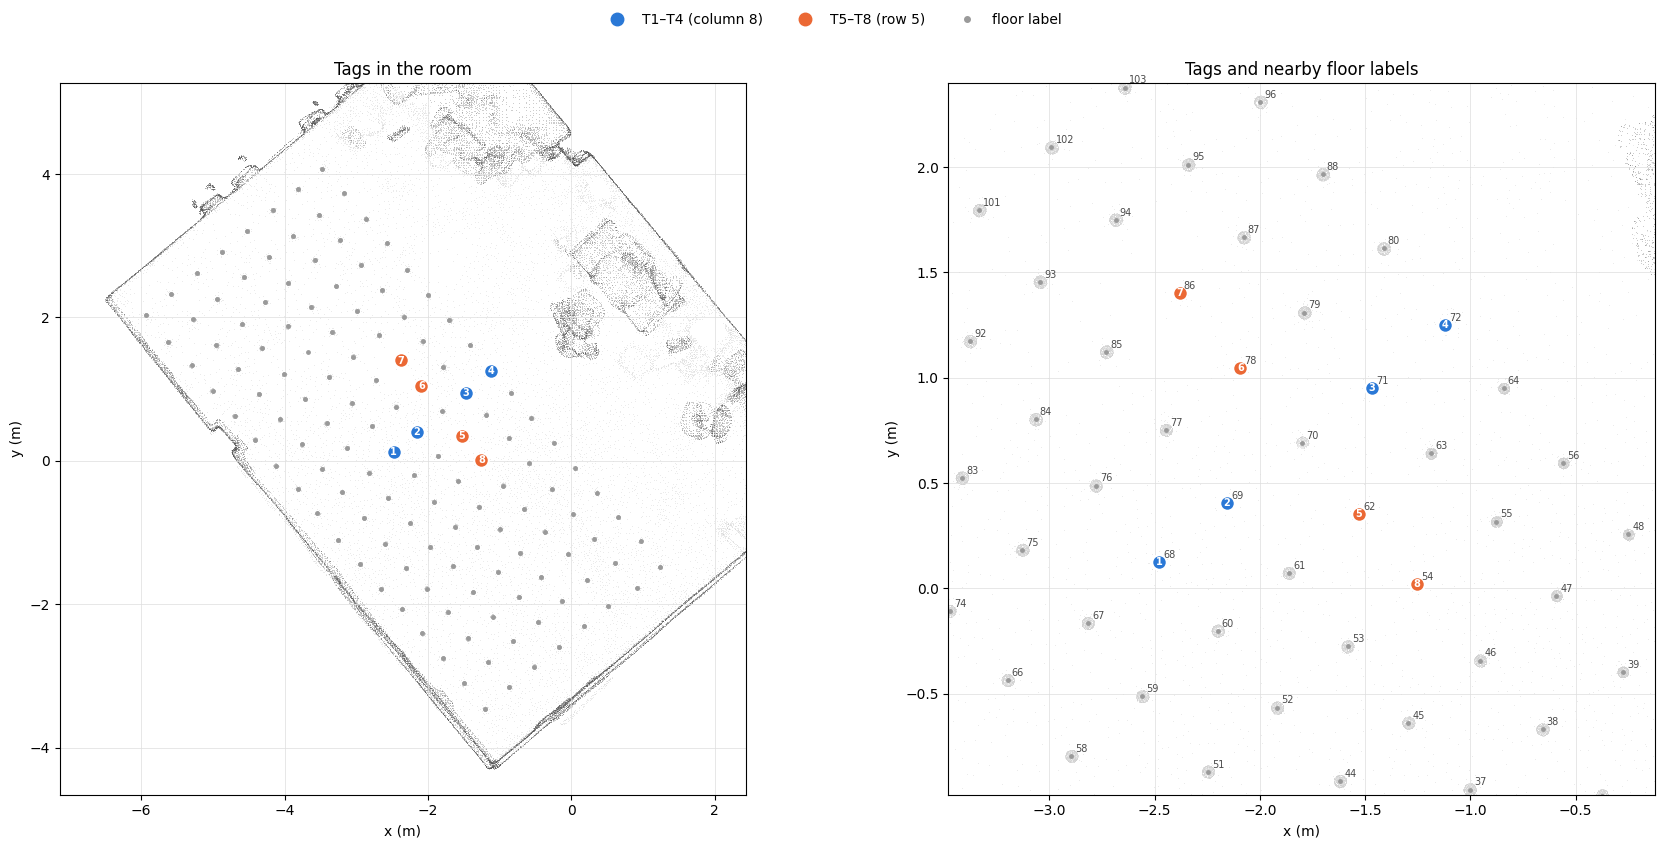

In [159]:
def tag_color(tag):
    for color, tags in zip(GROUP_COLORS, TAG_GROUPS.values()):
        if int(tag) in tags:
            return color
    return "#333333"


def draw_tags(ax, pos, size=110, fontsize=7):
    for tag, r in pos.iterrows():
        color = tag_color(tag)
        ax.scatter(r.x, r.y, s=size, color=color, edgecolors="white", linewidths=1.5, zorder=3)
        ax.annotate(tag, (r.x, r.y), ha="center", va="center", fontsize=fontsize, color="white",
                    fontweight="bold", zorder=4)


fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
for ax, zoom in zip(axes, (False, True)):
    draw_room(ax)
    draw_tags(ax, ref)
    if zoom:
        pad = 1.0
        x0, x1 = ref["x"].min() - pad, ref["x"].max() + pad
        y0, y1 = ref["y"].min() - pad, ref["y"].max() + pad
        near = markers[markers["x"].between(x0, x1) & markers["y"].between(y0, y1)]
        for lab, r in near.iterrows():
            ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points", fontsize=7,
                        color="#4a4a4a")
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_title("Tags and nearby floor labels")
    else:
        pad = 1.2
        ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
        ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
        ax.set_title("Tags in the room")
    ax.grid(True, color="#dddddd", lw=0.5)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
           for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
handles.append(plt.Line2D([], [], marker="o", ls="", color="#9a9a9a", markersize=4, label="floor label"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## Bidirectional phase and attenuation: `[exp][T1][T2][freq]`

The same as the room sweep and metal-wall notebooks. For a pair `1 < 2` (by tag number), subscript `1` is the row
with **Rx = T1** (Tx = T2) and `2` the row with **Rx = T2** (Tx = T1), matched per run:

$$\hat\alpha_{12} = \frac{1}{2}\left(\frac{\hat\beta_1}{\hat V_2} + \frac{\hat\beta_2}{\hat V_1}\right) \qquad
\hat\theta_{12} = \left(\frac{\hat\Theta_1 + \hat\Theta_2}{2}\right) \bmod \pi$$

- $\hat\Theta$ = `Unidirectional Phase (deg)` in radians → $\hat\theta_{12}$ (`theta_data`) in $[0, \pi)$
- $\hat\beta$ = `Unidirectional beta`, $\hat V$ = `Unidirectional V` → $\hat\alpha_{12}$ (`alpha_data`)
- `time_a (s)`, `time_b (s)` in `bidir`: the start times (`MPP Start Time (s)`) of the two unidirectional MPPs
  (Rx = T1 and Rx = T2) that give each θ̂ / α̂ row, in seconds from the first MPP of that experiment (which is at 0)

Each entry is the median over the runs at that frequency. θ̂ is an angle mod π, so its runs are first moved onto
the branch of their circular mean (`median_mod_pi`), which keeps runs on both sides of the 0 / π wrap together.

Only experiments with a CSV **and** positions are loaded. The `Channel_*_voltages` columns are skipped, since they
make the files large.

In [160]:
def load_csv(exp_dir, with_voltages=False):
    f = next(Path(exp_dir).glob("*.csv"))
    cols = pd.read_csv(f, nrows=0).columns
    usecols = cols if with_voltages else [c for c in cols if "voltages" not in c.lower()]
    return pd.read_csv(f, usecols=usecols)


def tag_num(name):
    return int(str(name).replace("Tag", ""))


def bidirectional(df):
    # Join each Rx=a/Tx=b row with its Rx=b/Tx=a counterpart (a < b) and compute THETA, alpha.
    keep = ["Rx", "Tx", "Frequency (MHz)", "Run Exp Num", "MPP Start Time (s)",
            "Unidirectional Phase (deg)", "Unidirectional V", "Unidirectional beta"]
    d = df[keep].copy()
    # time of each MPP in seconds, 0 = start of the first unidirectional MPP in this experiment
    d["time (s)"] = d["MPP Start Time (s)"] - d["MPP Start Time (s)"].min()
    fwd = d[d["Rx"].map(tag_num) < d["Tx"].map(tag_num)]    # Rx = a, Tx = b
    rev = d[d["Rx"].map(tag_num) > d["Tx"].map(tag_num)]    # Rx = b, Tx = a
    m = fwd.merge(rev, left_on=["Rx", "Tx", "Frequency (MHz)", "Run Exp Num"],
                  right_on=["Tx", "Rx", "Frequency (MHz)", "Run Exp Num"],
                  suffixes=("_a", "_b"), validate="one_to_one")
    th_a = np.deg2rad(m["Unidirectional Phase (deg)_a"])
    th_b = np.deg2rad(m["Unidirectional Phase (deg)_b"])
    m["THETA"] = ((th_a + th_b) / 2) % np.pi
    m["alpha"] = 0.5 * (m["Unidirectional beta_a"] / m["Unidirectional V_b"]
                        + m["Unidirectional beta_b"] / m["Unidirectional V_a"])
    m = m.rename(columns={"Rx_a": "T1", "Tx_a": "T2", "time (s)_a": "time_a (s)", "time (s)_b": "time_b (s)"})
    return m.sort_values(["time_a (s)", "time_b (s)"]).reset_index(drop=True)


def median_mod_pi(x):
    # median of mod-π angles: move every run onto the branch of their circular mean first, so runs on both sides
    # of the 0 / π wrap are not split apart, then take the median and wrap it back into [0, π)
    x = np.asarray(x, float)
    c = (np.angle(np.mean(np.exp(2j * x))) / 2) % np.pi
    return float((c + np.median((x - c + np.pi / 2) % np.pi - np.pi / 2)) % np.pi)


def to_nested(m, col, reduce=np.median):
    # -> {T1: {T2: {freq: median over runs}}} with tags in numeric order
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)", "Run Exp Num"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = float(reduce(g[col].to_numpy()))
    return out


csv_exps = [d.name for d in exp_dirs if any(d.glob("*.csv")) and positions[d.name] is not None]
data = {name: load_csv(DATA_DIR / name) for name in csv_exps}
bidir = {name: bidirectional(df) for name, df in data.items()}
theta_data = {name: to_nested(m, "THETA", median_mod_pi) for name, m in bidir.items()}
alpha_data = {name: to_nested(m, "alpha") for name, m in bidir.items()}

for name, m in bidir.items():
    print(f"exp {name}: {len(m)} (pair, freq, run) rows, {m.groupby(['T1', 'T2']).ngroups} pairs, "
          f"{m['Frequency (MHz)'].nunique()} freqs, runs {m['Run Exp Num'].min()}–{m['Run Exp Num'].max()}, "
          f"MPP times 0–{max(m['time_a (s)'].max(), m['time_b (s)'].max()):.2f} s")

exp baseline4_excitermoved: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs 0–2, MPP times 0–128.56 s
exp walking1: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs 0–2, MPP times 0–133.02 s
exp walking2: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs 0–2, MPP times 0–126.84 s
exp walking3: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs 0–2, MPP times 0–126.98 s
exp baseline915: 1960 (pair, freq, run) rows, 28 pairs, 1 freqs, runs 0–69, MPP times 0–149.38 s
exp walking915_1: 1960 (pair, freq, run) rows, 28 pairs, 1 freqs, runs 0–69, MPP times 0–140.68 s
exp walking915_2: 1960 (pair, freq, run) rows, 28 pairs, 1 freqs, runs 0–69, MPP times 0–146.75 s


## Link measurements over time: `links[exp][T1][T2][freq]`

θ̂ and α̂ above are medians over the runs. For tracking, every run is kept instead: each entry of `links` is a
`LinkSeries` with one value per run, in time order:

- `time_dir1`: time of the Rx = T1 (Tx = T2) MPP, s from the first MPP of the experiment
- `time_dir2`: time of the Rx = T2 (Tx = T1) MPP, s
- `theta`: θ̂₁₂ in $[0, \pi)$ (rad), `attn`: α̂₁₂
- `time`: the average of `time_dir1` and `time_dir2`, which the time series below are plotted against


In [161]:
from dataclasses import dataclass


@dataclass
class LinkSeries:
    # one link (T1, T2) at one frequency, one value per run, sorted by time
    time_dir1: np.ndarray   # s, Rx = T1 MPP
    time_dir2: np.ndarray   # s, Rx = T2 MPP
    theta: np.ndarray       # rad, [0, π)
    attn: np.ndarray        # α̂

    @property
    def time(self):
        # average time of the two directions
        return (self.time_dir1 + self.time_dir2) / 2


def to_links(m):
    # -> {T1: {T2: {freq: LinkSeries}}} with tags in numeric order
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        g = g.assign(_t=(g["time_a (s)"] + g["time_b (s)"]) / 2).sort_values("_t")
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = LinkSeries(
            time_dir1=g["time_a (s)"].to_numpy(), time_dir2=g["time_b (s)"].to_numpy(),
            theta=g["THETA"].to_numpy(), attn=g["alpha"].to_numpy())
    return out


links = {name: to_links(m) for name, m in bidir.items()}


## Timing statistics (CDFs)

All three are computed per bidirectional link (T1, T2) from `links`, using the average time of the two MPPs
(`LinkSeries.time`) as the time of a θ̂ / α̂ measurement:

1. **Gap between the two MPPs of one θ̂ / α̂**: `|time_dir2 − time_dir1|`, the time between the Rx = T1 and the
   Rx = T2 MPP that are combined into one bidirectional value.
2. **Time between cycles, any frequency**: the time between consecutive measurements of the same link, whatever
   the frequency, i.e. how often a link gets a new θ̂ / α̂.
3. **Time between cycles, same frequency**: the time between consecutive measurements of the same link at the
   same frequency.

Experiments are pooled into two groups: multi-frequency (775–995 MHz) and single-frequency (915 MHz). With a
single frequency, 2 and 3 are the same.


,group,freqs
experiment,,
baseline4_excitermoved,multi-frequency,23
walking1,multi-frequency,23
walking2,multi-frequency,23
walking3,multi-frequency,23
baseline915,single-frequency (915 MHz),1
walking915_1,single-frequency (915 MHz),1
walking915_2,single-frequency (915 MHz),1


,n,mean,min,p5,median,p95,max
statistic,,,,,,,
gap between the two MPPs of one θ̂ / α̂,7728,0.150,0.050,0.050,0.150,0.300,0.350
"time between cycles of a link, any frequency",7616,1.890,1.579,1.672,1.792,1.923,9.980
"time between cycles of a link, same frequency",5152,43.831,42.472,42.636,43.595,44.560,50.788


,n,mean,min,p5,median,p95,max
statistic,,,,,,,
gap between the two MPPs of one θ̂ / α̂,5880,0.150,0.050,0.050,0.150,0.300,0.350
"time between cycles of a link, any frequency",5796,2.105,1.817,1.894,2.019,2.180,10.258
"time between cycles of a link, same frequency",5796,2.105,1.817,1.894,2.019,2.180,10.258


,gap between the two MPPs of one θ̂ / α̂,"time between cycles of a link, any frequency","time between cycles of a link, same frequency"
experiment,,,
baseline4_excitermoved,0.150,1.807,44.001
walking1,0.150,1.769,42.945
walking2,0.150,1.804,43.591
walking3,0.150,1.788,43.572
baseline915,0.150,2.101,2.101
walking915_1,0.150,2.015,2.015
walking915_2,0.150,1.952,1.952


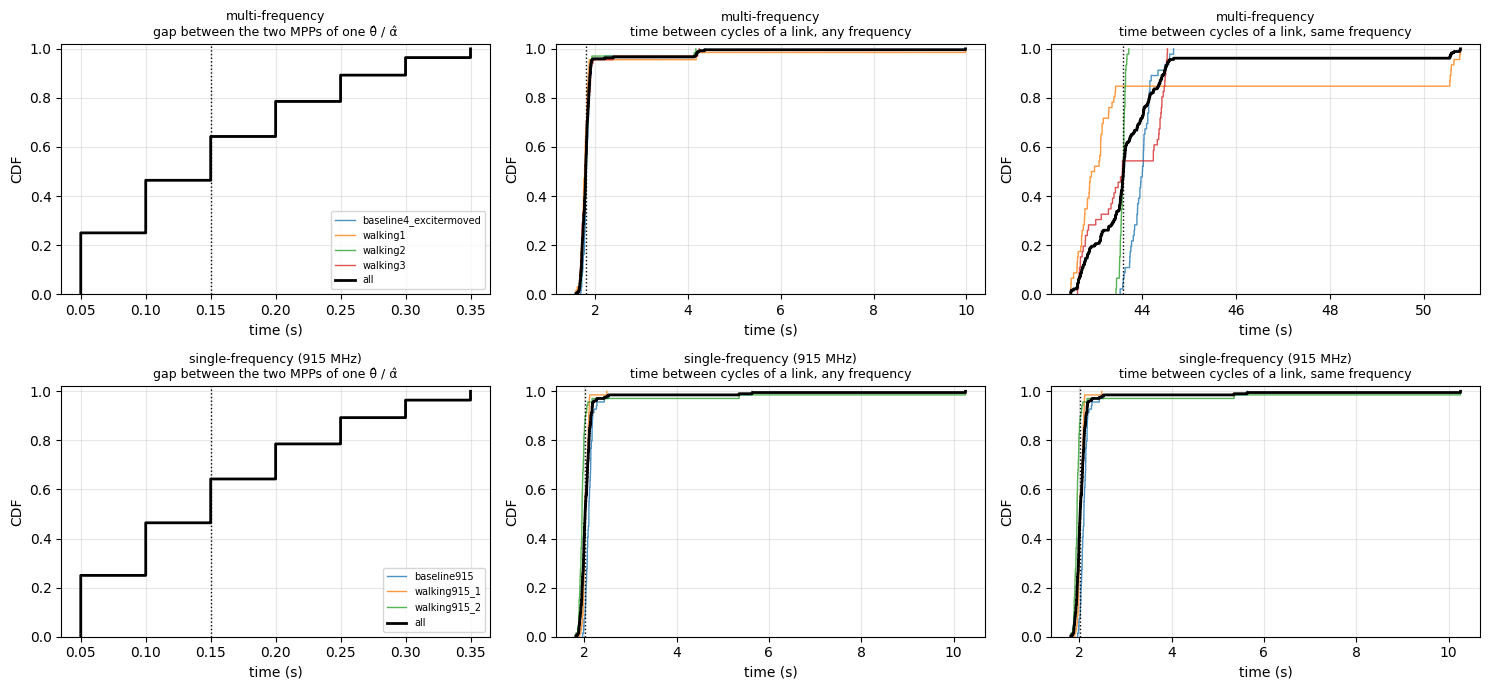

In [162]:
def timing_samples(exp_links):
    # -> dict of 1-D arrays (s) for the three statistics, pooled over all links of one experiment
    gap, any_f, same_f = [], [], []
    for t1, by_t2 in exp_links.items():
        for t2, by_f in by_t2.items():
            for s in by_f.values():
                gap.append(np.abs(s.time_dir2 - s.time_dir1))
                same_f.append(np.diff(np.sort(s.time)))
            any_f.append(np.diff(np.sort(np.concatenate([s.time for s in by_f.values()]))))
    return {"gap": np.concatenate(gap), "any_freq": np.concatenate(any_f), "same_freq": np.concatenate(same_f)}


def n_freqs(exp):
    return bidir[exp]["Frequency (MHz)"].nunique()


GROUPS = {
    "multi-frequency": [e for e in links if n_freqs(e) > 1],
    "single-frequency (915 MHz)": [e for e in links if n_freqs(e) == 1],
}
STATS = {
    "gap": "gap between the two MPPs of one θ̂ / α̂",
    "any_freq": "time between cycles of a link, any frequency",
    "same_freq": "time between cycles of a link, same frequency",
}

per_exp = {e: timing_samples(links[e]) for e in links}
pooled = {g: {k: np.concatenate([per_exp[e][k] for e in exps]) for k in STATS} for g, exps in GROUPS.items()}

from IPython.display import display

# which experiments are in which group
display(pd.DataFrame({"group": [g for g, exps in GROUPS.items() for _ in exps],
                      "freqs": [n_freqs(e) for exps in GROUPS.values() for e in exps]},
                     index=pd.Index([e for exps in GROUPS.values() for e in exps], name="experiment"))
        .style.set_caption("Experiments"))

# one summary table per group, times in seconds
COLS = {"n": len, "mean": np.mean, "min": np.min, "p5": lambda x: np.percentile(x, 5),
        "median": np.median, "p95": lambda x: np.percentile(x, 95), "max": np.max}
summary = {}
for g in GROUPS:
    summary[g] = pd.DataFrame({name: [f(pooled[g][k]) for k in STATS] for name, f in COLS.items()},
                              index=pd.Index(STATS.values(), name="statistic"))
    display(summary[g].style
            .format({c: "{:.3f}" for c in COLS if c != "n"} | {"n": "{:.0f}"})
            .set_caption(f"{g}: times in seconds"))

# median of each statistic per experiment, times in seconds
display(pd.DataFrame({label: {e: np.median(per_exp[e][k]) for e in per_exp} for k, label in STATS.items()})
        .rename_axis("experiment").style.format("{:.3f}")
        .set_caption("Median per experiment: times in seconds"))

def plot_cdf(ax, x, **kw):
    x = np.sort(x)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", **kw)


fig, axes = plt.subplots(len(GROUPS), len(STATS), figsize=(15, 7), squeeze=False)
for row, (g, exps) in zip(axes, GROUPS.items()):
    colors = plt.cm.tab10(np.arange(len(exps)) % 10)
    for ax, (k, label) in zip(row, STATS.items()):
        for e, col in zip(exps, colors):
            plot_cdf(ax, per_exp[e][k], color=col, lw=1, alpha=0.8, label=e)
        plot_cdf(ax, pooled[g][k], color="k", lw=2, label="all")
        ax.axvline(np.median(pooled[g][k]), color="k", ls=":", lw=1)
        ax.set_title(f"{g}\n{label}", fontsize=9)
        ax.set_xlabel("time (s)")
        ax.set_ylabel("CDF")
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()


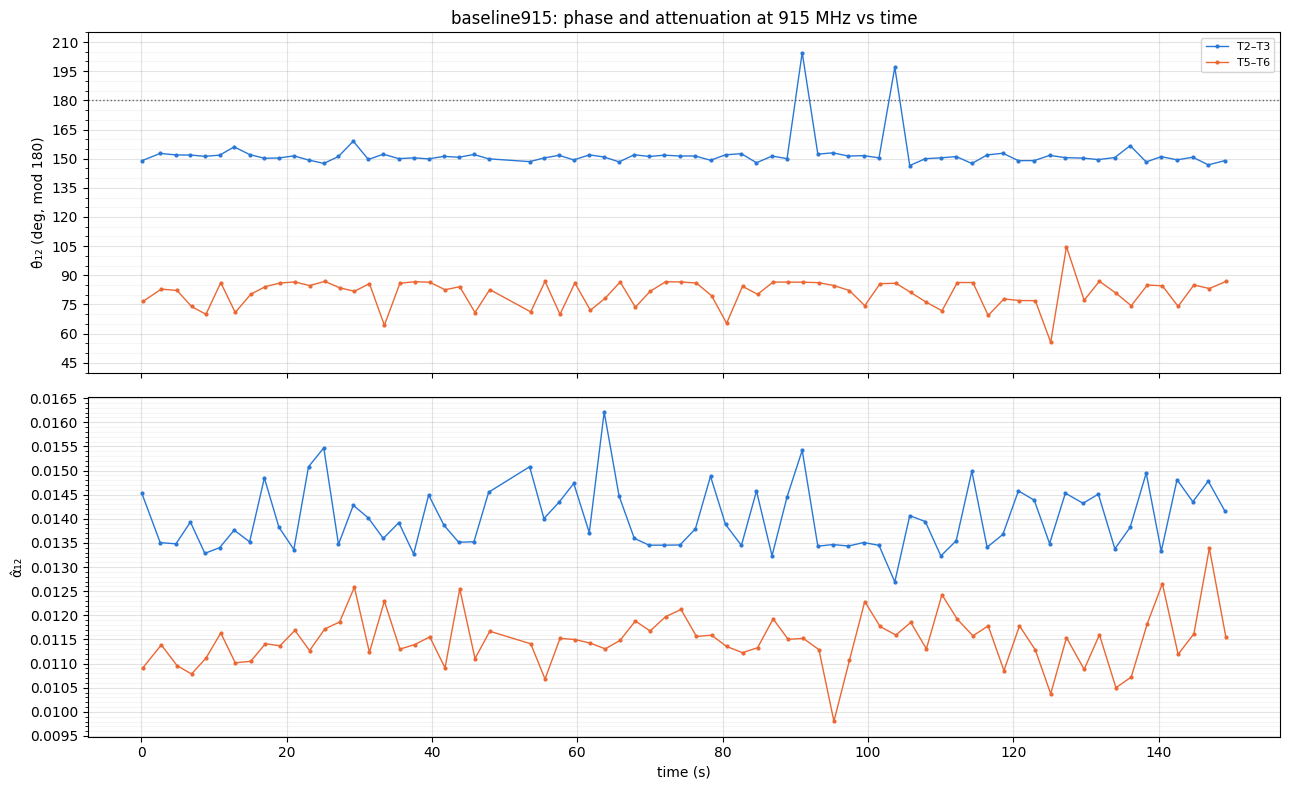

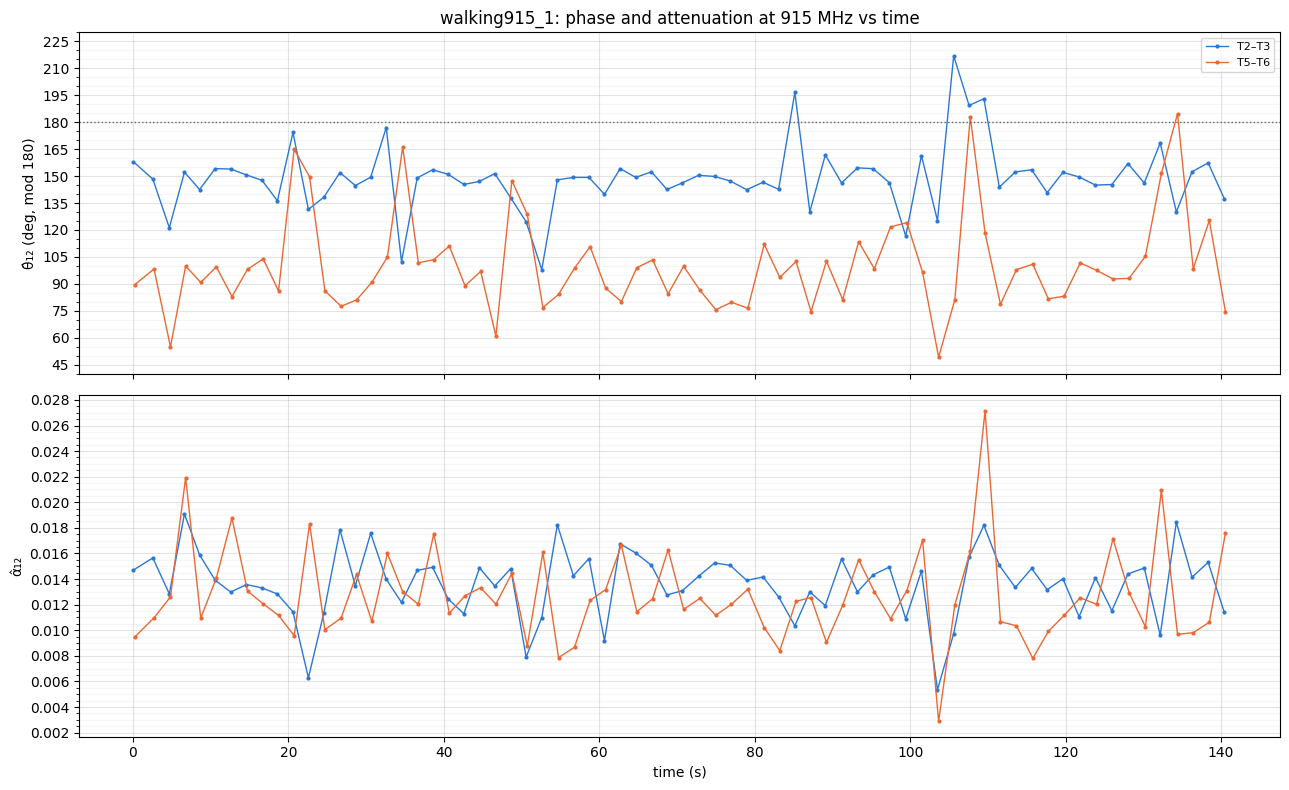

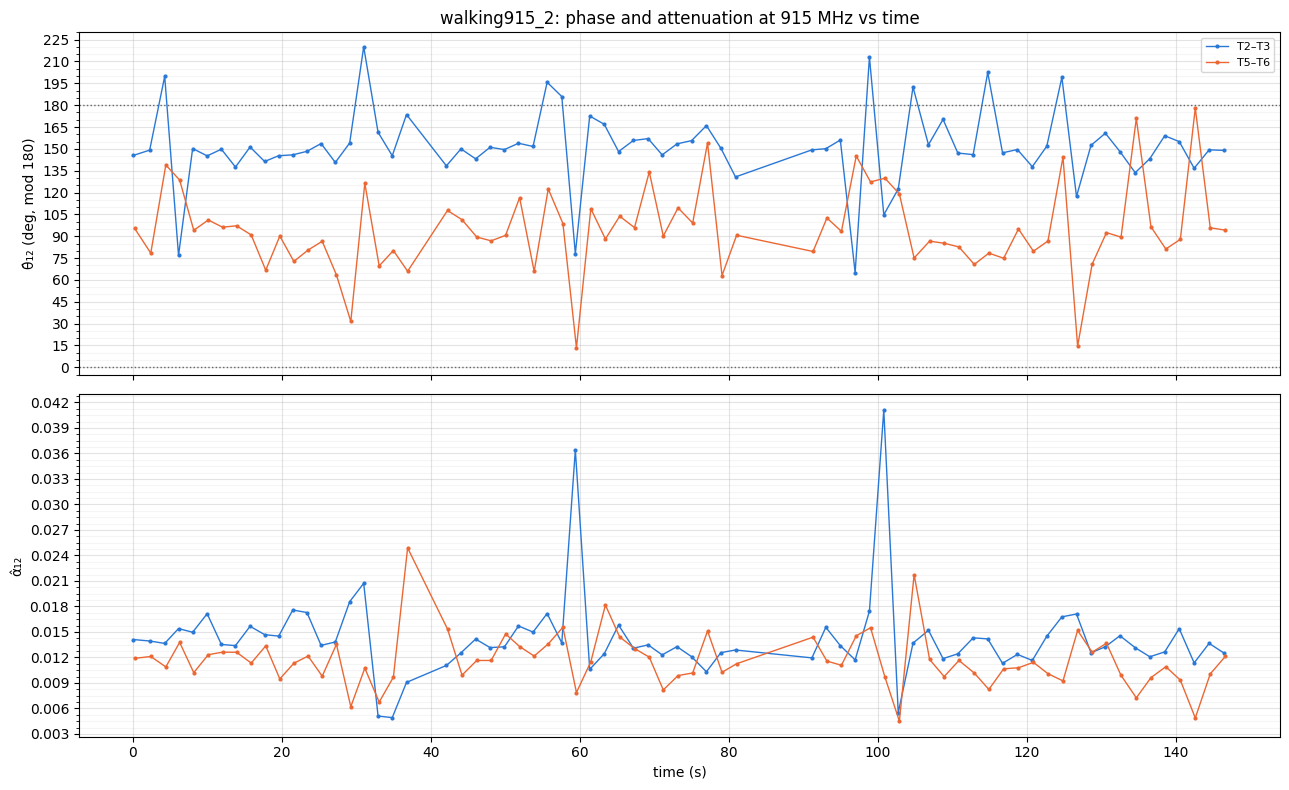

In [163]:
# θ̂ and α̂ of selected links at 915 MHz against time, one figure per experiment
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator

TS_EXPS = ["baseline915", "walking915_1", "walking915_2"]
TS_FREQ = 915
TS_LINKS = [(2, 3), (5, 6)]          # (T1, T2) tag numbers, T1 < T2
TS_COLORS = ["#2a78d6", "#eb6834"]


def find_link(exp_links, a, b):
    # LinkSeries of tags a < b at TS_FREQ (keys of `links` are the tag names as in the CSV)
    for t1, by_t2 in exp_links.items():
        for t2, by_f in by_t2.items():
            if (tag_num(t1), tag_num(t2)) == (a, b):
                return by_f[TS_FREQ]
    raise KeyError(f"link T{a}–T{b} not found")


def phase_deg_unwrapped(theta):
    # θ̂ (rad, mod π) -> degrees, each sample moved by a multiple of 180° to within ±90° of the link's circular
    # mean, so the distance between any two plotted points is the wrapped one, min(|a − b|, 180 − |a − b|),
    # whenever both are on the same side of the mean (e.g. 150° and 30° plot as 150° and 210°, 60° apart).
    # Values outside 0–180 are the same angle ± 180°.
    center = np.rad2deg(np.angle(np.mean(np.exp(2j * theta))) / 2) % 180
    d = np.rad2deg(theta)
    return center + ((d - center + 90) % 180 - 90)


def style_phase_axis(ax, ys):
    # y range from the plotted (unwrapped) phases, 15° labels, 5° minor grid, dotted lines at the 0 / 180° wrap
    lo, hi = min(y.min() for y in ys), max(y.max() for y in ys)
    ax.set_ylim(np.floor(lo / 15) * 15 - 5, np.ceil(hi / 15) * 15 + 5)
    ax.yaxis.set_major_locator(MultipleLocator(15))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    for w in (0, 180):
        if ax.get_ylim()[0] < w < ax.get_ylim()[1]:
            ax.axhline(w, color="0.4", ls=":", lw=1)
    ax.set_ylabel("θ̂₁₂ (deg, mod 180)")


for exp in TS_EXPS:
    fig, (ax_th, ax_at) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    phases = []
    for (a, b), col in zip(TS_LINKS, TS_COLORS):
        s = find_link(links[exp], a, b)
        label = f"T{a}–T{b}"
        ph = phase_deg_unwrapped(s.theta)
        phases.append(ph)
        ax_th.plot(s.time, ph, ".-", color=col, ms=4, lw=1, label=label)
        ax_at.plot(s.time, s.attn, ".-", color=col, ms=4, lw=1, label=label)
    style_phase_axis(ax_th, phases)
    ax_at.set_ylabel("α̂₁₂")
    ax_at.yaxis.set_major_locator(MaxNLocator(nbins=15))
    ax_at.yaxis.set_minor_locator(AutoMinorLocator())
    ax_at.set_xlabel("time (s)")
    for ax in (ax_th, ax_at):
        ax.grid(which="major", alpha=0.35)
        ax.grid(which="minor", alpha=0.12)
    ax_th.set_title(f"{exp}: phase and attenuation at {TS_FREQ} MHz vs time")
    ax_th.legend(fontsize=8, loc="upper right")
    fig.tight_layout()
    plt.show()

T2–T3: empty-room check, score vs baseline noise must exceed 38.22 (p99 of baseline915)
T5–T6: empty-room check, score vs baseline noise must exceed 5.27 (p99 of baseline915)


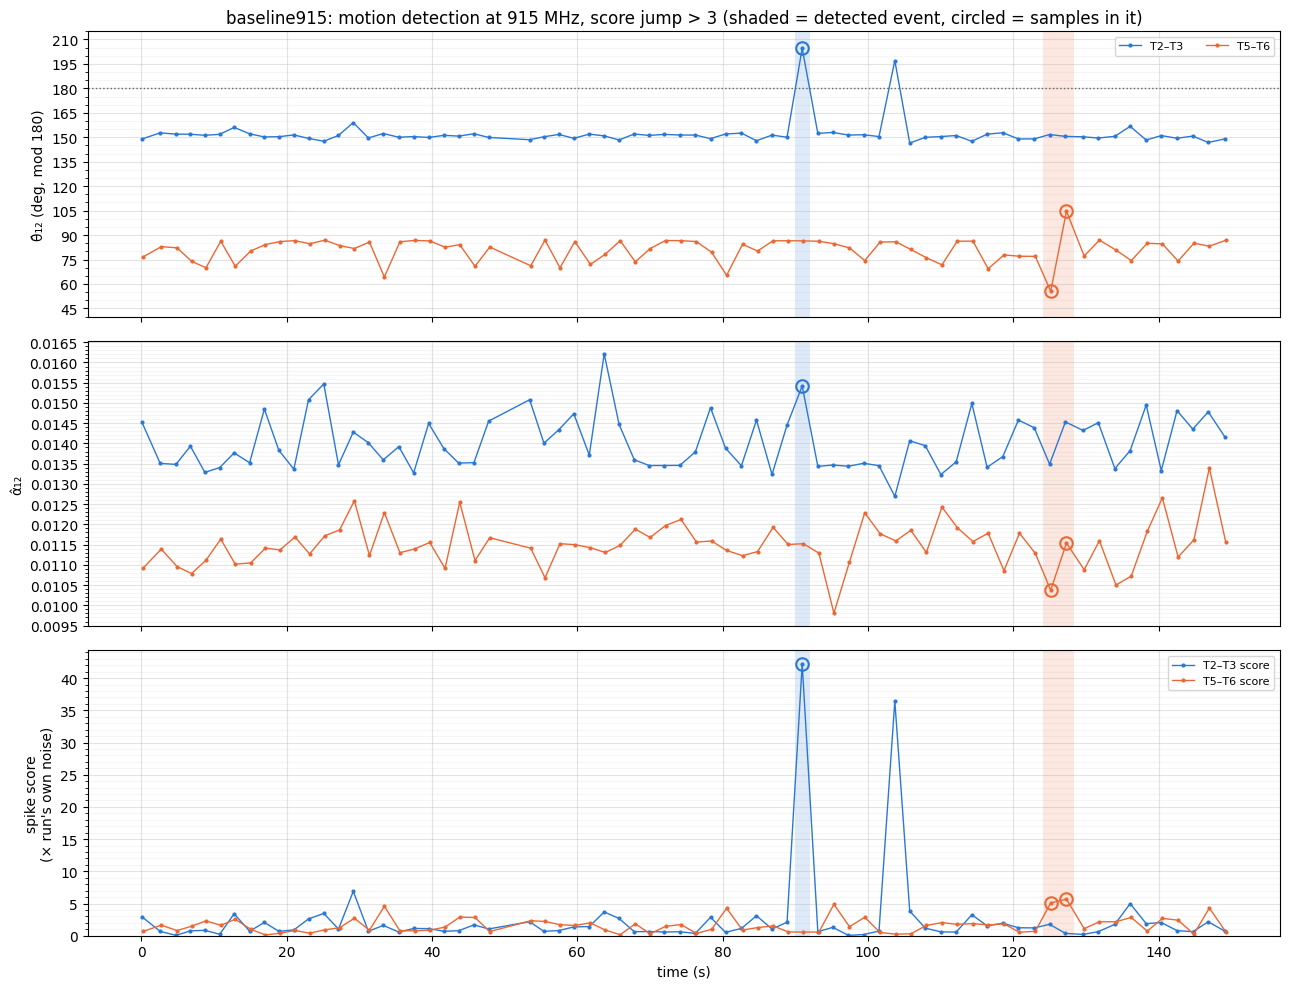

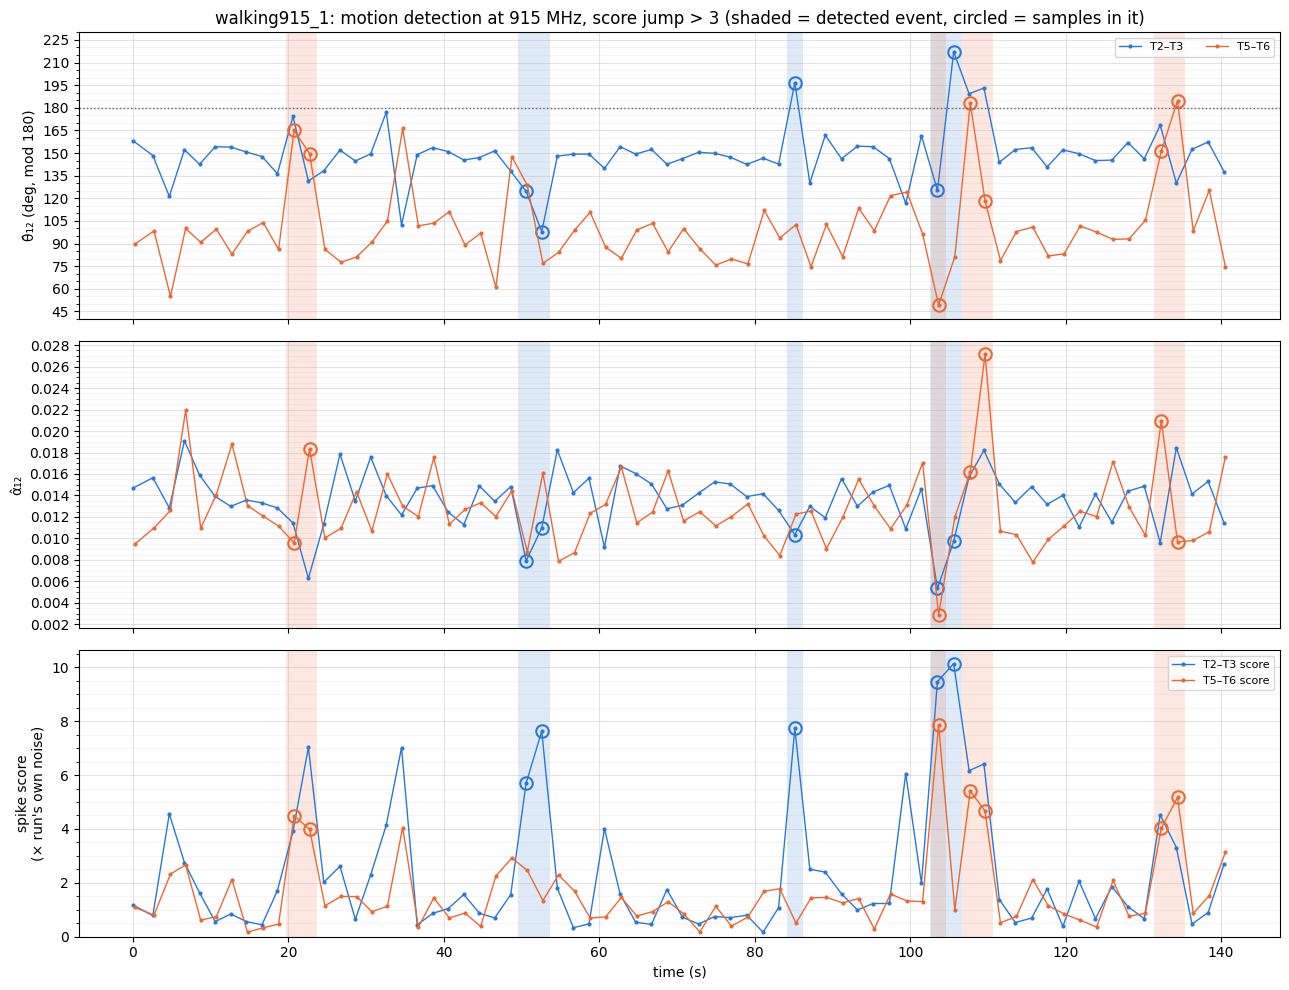

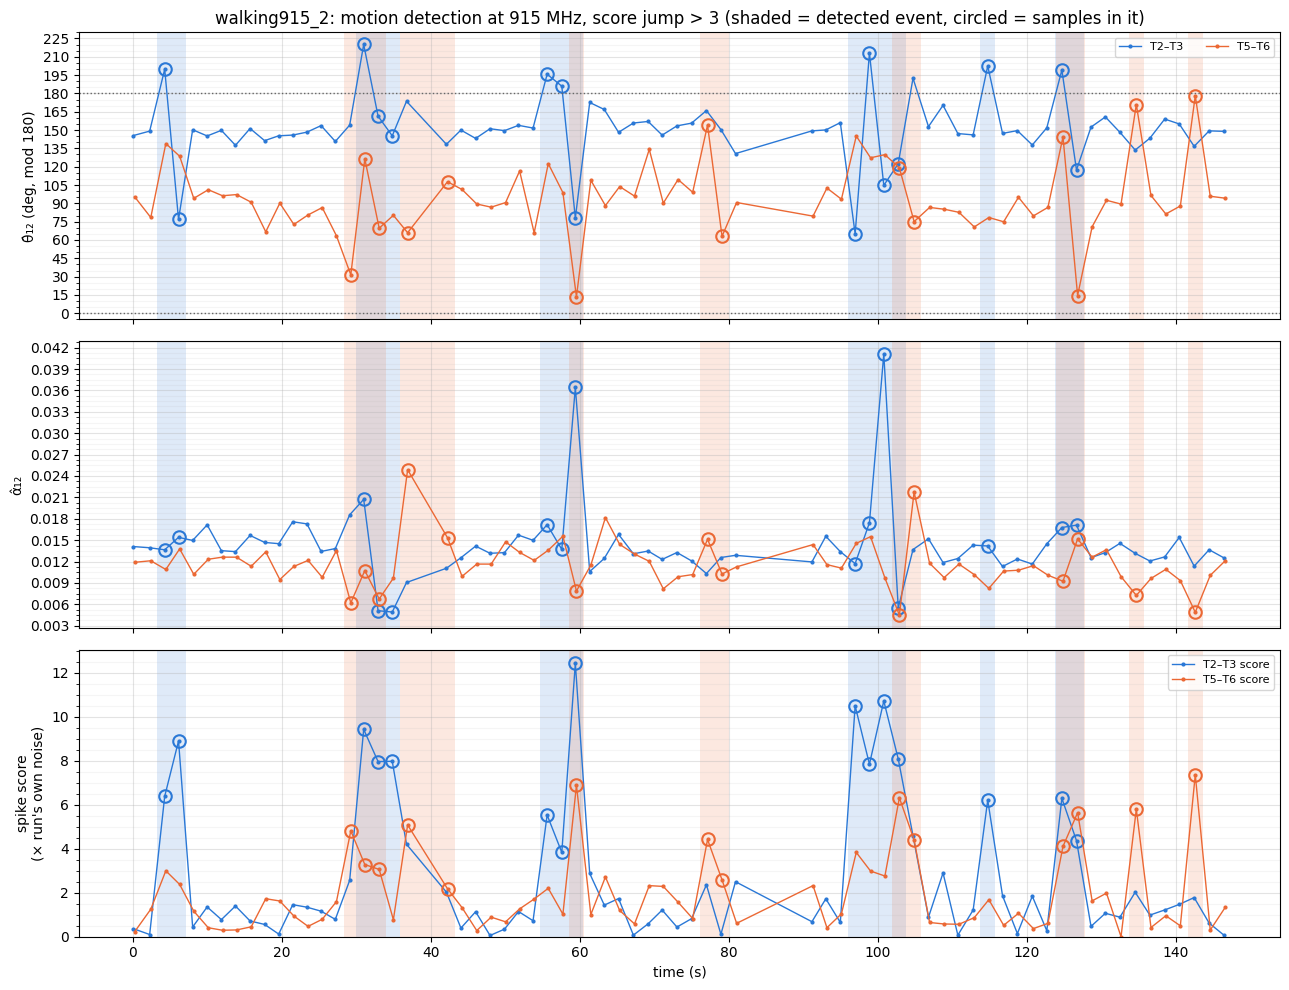

,experiment,links,t_start (s),t_end (s),t_peak (s),peak score,n samples
0,baseline915,T2–T3,90.96,90.96,90.96,42.18,1
1,baseline915,T5–T6,125.16,127.33,127.33,5.67,2
2,walking915_1,T2–T3,50.59,52.60,52.60,7.63,2
3,walking915_1,T2–T3,85.16,85.16,85.16,7.73,1
4,walking915_1,T2–T3,103.50,105.59,105.59,10.14,2
5,walking915_1,T5–T6,20.74,22.73,20.74,4.48,2
6,walking915_1,T5–T6,103.65,103.65,103.65,7.85,1
7,walking915_1,T5–T6,107.73,109.63,107.73,5.41,2
8,walking915_1,T5–T6,132.31,134.39,134.39,5.17,2
9,walking915_2,T2–T3,4.26,6.12,6.12,8.90,2


In [164]:
# Motion detection: sudden spikes / dips in θ̂ and α̂ relative to a slow rolling median.
# Works on a GROUP of links (one link is a group of one). All links are measured once per run (cycle), within
# ≈ 0.25 s of each other, and runs are ≈ 2 s apart, so sample k of every link is the same run.
#   score per link = √((phase residual / σ_phase)² + (log-α residual / σ_logα)²), σ = the run's own robust noise
#   group score    = RMS over the links of the group (= the link score for a single link)
# Events come from jumps in the group score:
#   1. a window OPENS when the score rises by more than `delta` from one sample to the next, and stays open until
#      the score has come back down by more than `delta` from the highest score inside the window (measured from
#      the peak so a fall spread over a few samples still closes it). A window that never closes runs to the end.
#   2. the window is kept only if its largest group score vs baseline915 noise is above the MD_BASE_PCT percentile
#      of the same score in baseline915 (rejects jumps no bigger than the glitches of the empty room)
# Every function takes `source(exp, a, b) -> LinkSeries` (default: the link at TS_FREQ) and the `baseline` experiment,
# so the same algorithm runs on other features, e.g. the baseline-subtracted multi-frequency series further below.
# Uses TS_EXPS, TS_FREQ, TS_LINKS, TS_COLORS, find_link, phase_deg_unwrapped, style_phase_axis from above.
MD_BASELINE = "baseline915"
MD_WINDOW = 11        # rolling-median window (samples, ≈ 2 s each): long enough to ignore a 1–2 sample event
MD_DELTA = 3.0        # condition 1 for single links: jump in score (× the run's own noise) that opens / closes a window
MD_BASE_PCT = 99      # condition 2: percentile of the baseline915 scores


def rolling_median(x, window=MD_WINDOW):
    return pd.Series(x).rolling(window, center=True, min_periods=1).median().to_numpy()


def residuals(s):
    # -> (phase residual in deg, log-attenuation residual) of every sample against the rolling median
    u = np.exp(2j * s.theta)                                   # doubled angle: no wrap at 0 / 180°
    ref = rolling_median(u.real) + 1j * rolling_median(u.imag)
    d_phase = np.rad2deg(np.angle(u * np.conj(ref)) / 2)       # back to θ̂ units, in (−90°, 90°]
    assert np.all(s.attn > 0), "α̂ must be positive for log-attenuation"
    la = np.log(s.attn)
    d_att = la - rolling_median(la)
    return d_phase, d_att


def mad_scale(x):
    # robust standard deviation
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def combined_score(d_phase, d_att, scales):
    return np.hypot(d_phase / scales[0], d_att / scales[1])


def jump_windows(score, delta):
    # -> list of (first, last) sample indices: opens on a rise > delta from the previous sample, closes before the
    # first sample that is more than delta below the highest score so far in the window
    rise = np.diff(score, prepend=score[0])
    windows, k, n = [], 0, len(score)
    while k < n:
        if rise[k] > delta:
            peak, j = score[k], k + 1
            while j < n and peak - score[j] <= delta:
                peak = max(peak, score[j])
                j += 1
            windows.append((k, j - 1))
            k = j
        else:
            k += 1
    return windows


def link_name(a, b):
    return f"T{a}–T{b}"


def group_name(group):
    return link_name(*group[0]) if len(group) == 1 else "merged " + ", ".join(link_name(a, b) for a, b in group)


def link_915(exp, a, b):
    # default source: the link at TS_FREQ
    return find_link(links[exp], a, b)


_base_scales = {}


def base_scales(a, b, source=link_915, baseline=MD_BASELINE):
    # empty-room noise (σ_phase, σ_logα) of one link, cached
    key = (source, baseline, a, b)
    if key not in _base_scales:
        bp, ba = residuals(source(baseline, a, b))
        _base_scales[key] = (mad_scale(bp), mad_scale(ba))
    return _base_scales[key]


def group_scores(exp, group, source=link_915, baseline=MD_BASELINE):
    # -> time (mean over links per run), per-link scores (links × runs), group score, group score vs baseline noise
    t, per_link, per_link_base = [], [], []
    for a, b in group:
        s = source(exp, a, b)
        dp, da = residuals(s)
        t.append(s.time)
        per_link.append(combined_score(dp, da, (mad_scale(dp), mad_scale(da))))
        per_link_base.append(combined_score(dp, da, base_scales(a, b, source, baseline)))
    per_link, per_link_base = np.array(per_link), np.array(per_link_base)
    rms = lambda x: np.sqrt((x ** 2).mean(axis=0))
    return np.mean(t, axis=0), per_link, rms(per_link), rms(per_link_base)


def detect_motion(exp, group, delta, source=link_915, baseline=MD_BASELINE):
    # -> dict with t, per_link, score, base_thresh, events (list of dicts), in_event (bool per sample)
    t, per_link, score, base_score = group_scores(exp, group, source, baseline)
    base_thresh = np.percentile(group_scores(baseline, group, source, baseline)[3], MD_BASE_PCT)
    events, in_event = [], np.zeros(len(t), bool)
    for i, j in jump_windows(score, delta):
        if base_score[i:j + 1].max() <= base_thresh:
            continue
        in_event[i:j + 1] = True
        peak = i + int(np.argmax(score[i:j + 1]))
        e = {"t_start (s)": t[i], "t_end (s)": t[j], "t_peak (s)": t[peak], "peak score": score[peak],
             "n samples": j - i + 1}
        if len(group) > 1:
            # links that contribute most at the peak (link score above the group score)
            e["main links at peak"] = ", ".join(link_name(a, b) for (a, b), v in zip(group, per_link[:, peak])
                                                if v > score[peak])
        events.append(e)
    return dict(t=t, per_link=per_link, score=score, base_thresh=base_thresh, events=events, in_event=in_event)


def plot_motion(exp, groups, delta, colors, source=link_915, baseline=MD_BASELINE, what=f"at {TS_FREQ} MHz",
                phase_label=None, attn_label="α̂₁₂", phase_fn=phase_deg_unwrapped):
    # One figure: phase, attenuation and score of every group in `groups` (each a list of links), each with its own
    # colour and events. Single-link groups use the group colour for the link; in a merged group every link gets its
    # own colour, its link score is drawn thin and the merged score thick. -> list of event rows for the table
    fig, (ax_th, ax_at, ax_sc) = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
    phases, rows = [], []
    for group, col in zip(groups, colors):
        r = detect_motion(exp, group, delta, source, baseline)
        multi = len(group) > 1
        link_cols = plt.cm.tab10(np.arange(len(group)) % 10) if multi else [col]
        for (a, b), lc, sc in zip(group, link_cols, r["per_link"]):
            s = source(exp, a, b)
            ph = phase_fn(s.theta)
            phases.append(ph)
            ax_th.plot(s.time, ph, ".-", color=lc, ms=3 if multi else 4, lw=0.8 if multi else 1, label=link_name(a, b))
            ax_at.plot(s.time, s.attn, ".-", color=lc, ms=3 if multi else 4, lw=0.8 if multi else 1)
            if multi:
                ax_sc.plot(r["t"], sc, ".-", color=lc, ms=2, lw=0.6, alpha=0.5)
        t, score, flagged = r["t"], r["score"], r["in_event"]
        ax_sc.plot(t, score, ".-", color=col, ms=4, lw=1.4 if multi else 1,
                   label="merged (RMS over links)" if multi else f"{group_name(group)} score")

        # shade each event over all three panels, half a sample spacing either side; circle the samples in it
        half = np.median(np.diff(t)) / 2
        for e in r["events"]:
            for ax in (ax_th, ax_at, ax_sc):
                ax.axvspan(e["t_start (s)"] - half, e["t_end (s)"] + half, color=col, alpha=0.15, lw=0)
        ax_sc.plot(t[flagged], score[flagged], "o", mfc="none", mec=col, ms=9, mew=1.5)
        if not multi:
            s = source(exp, *group[0])
            ax_th.plot(t[flagged], phases[-1][flagged], "o", mfc="none", mec=col, ms=9, mew=1.5)
            ax_at.plot(t[flagged], s.attn[flagged], "o", mfc="none", mec=col, ms=9, mew=1.5)
        rows += [{"experiment": exp, "links": group_name(group), **e} for e in r["events"]]

    style_phase_axis(ax_th, phases)
    if phase_label:
        ax_th.set_ylabel(phase_label)
    ax_at.set_ylabel(attn_label)
    ax_at.yaxis.set_major_locator(MaxNLocator(nbins=15))
    ax_at.yaxis.set_minor_locator(AutoMinorLocator())
    ax_sc.set_ylabel("spike score\n(× run's own noise)")
    ax_sc.set_ylim(bottom=0)
    ax_sc.yaxis.set_minor_locator(AutoMinorLocator())
    ax_sc.set_xlabel("time (s)")
    for ax in (ax_th, ax_at, ax_sc):
        ax.grid(which="major", alpha=0.35)
        ax.grid(which="minor", alpha=0.12)
    ax_th.set_title(f"{exp}: motion detection {what}, score jump > {delta:g} "
                    f"(shaded = detected event, circled = samples in it)")
    ax_th.legend(fontsize=8, loc="upper right", ncol=3)
    ax_sc.legend(fontsize=8, loc="upper right")
    fig.tight_layout()
    plt.show()
    return rows


def run_motion(groups, delta, colors, exps=TS_EXPS, caption="Detected motion events", source=link_915,
               baseline=MD_BASELINE, **plot_kw):
    # plot every experiment and show one event table -> DataFrame of events.
    # plot_kw: what, phase_label, attn_label, phase_fn (θ̂ in rad -> plotted phase in deg)
    for group in groups:
        thr = np.percentile(group_scores(baseline, group, source, baseline)[3], MD_BASE_PCT)
        print(f"{group_name(group)}: empty-room check, score vs baseline noise must exceed {thr:.2f} "
              f"(p{MD_BASE_PCT} of {baseline})")
    events = pd.DataFrame([row for exp in exps
                           for row in plot_motion(exp, groups, delta, colors, source, baseline, **plot_kw)])
    display(events.style.format({c: "{:.2f}" for c in ["t_start (s)", "t_end (s)", "t_peak (s)", "peak score"]})
            .set_caption(caption) if len(events) else "no events detected")
    return events


# single links, each its own group
md_events = run_motion([[link] for link in TS_LINKS], MD_DELTA, TS_COLORS)

merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6: empty-room check, score vs baseline noise must exceed 17.65 (p99 of baseline915)


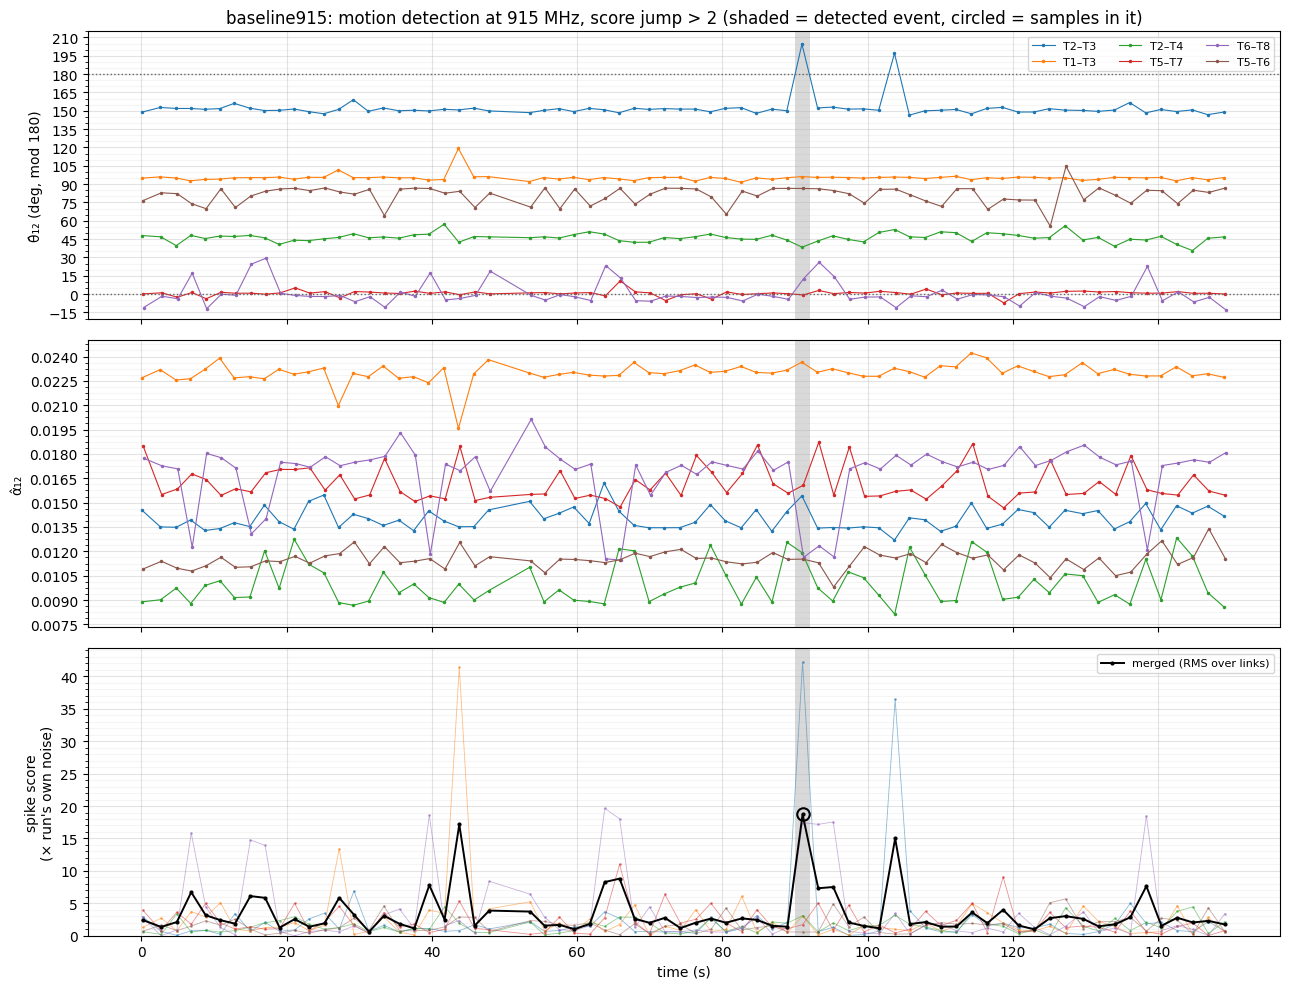

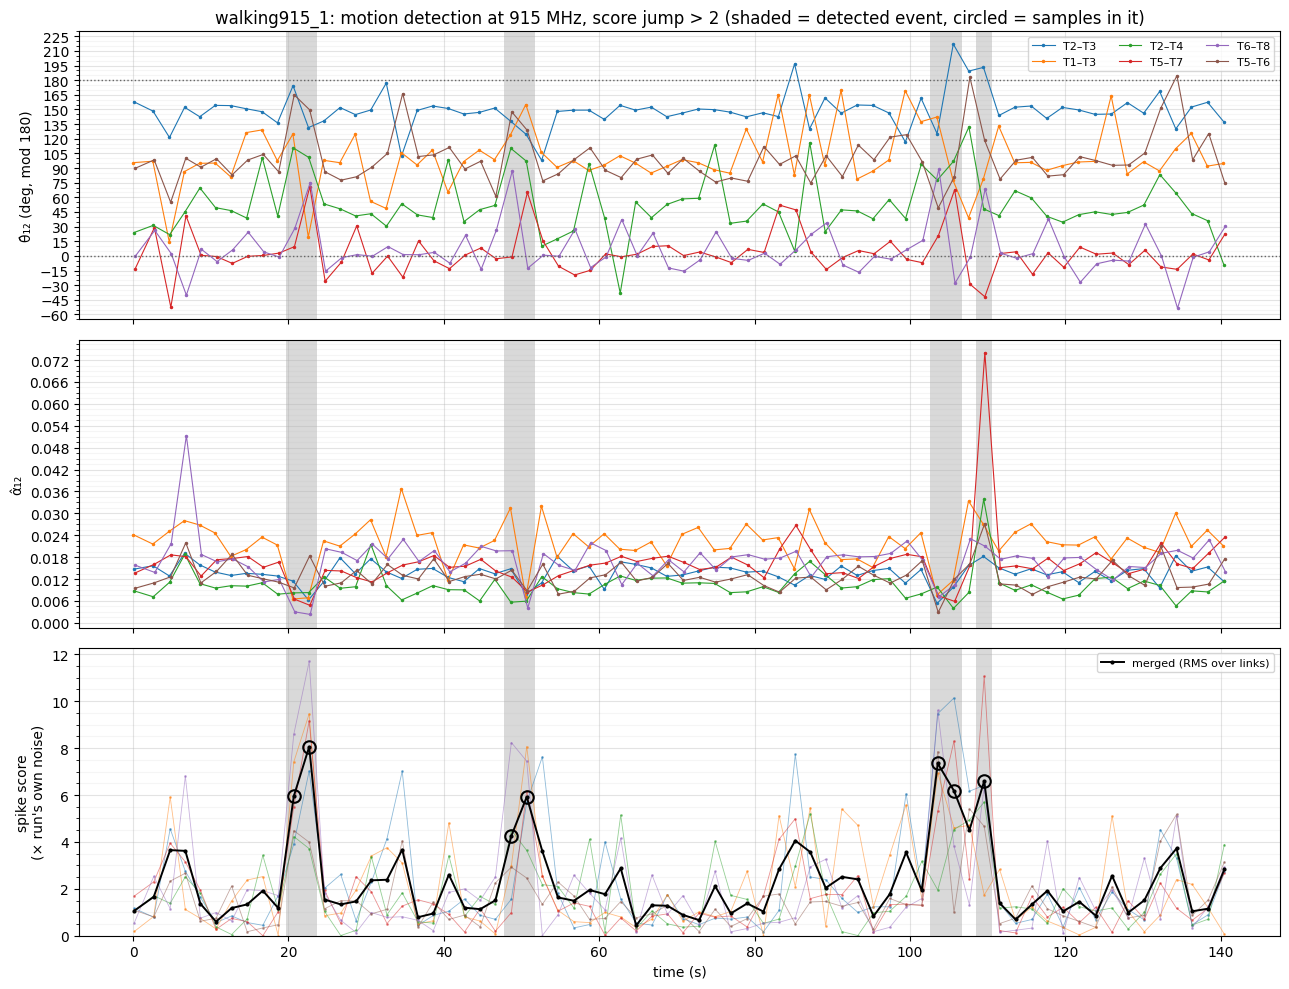

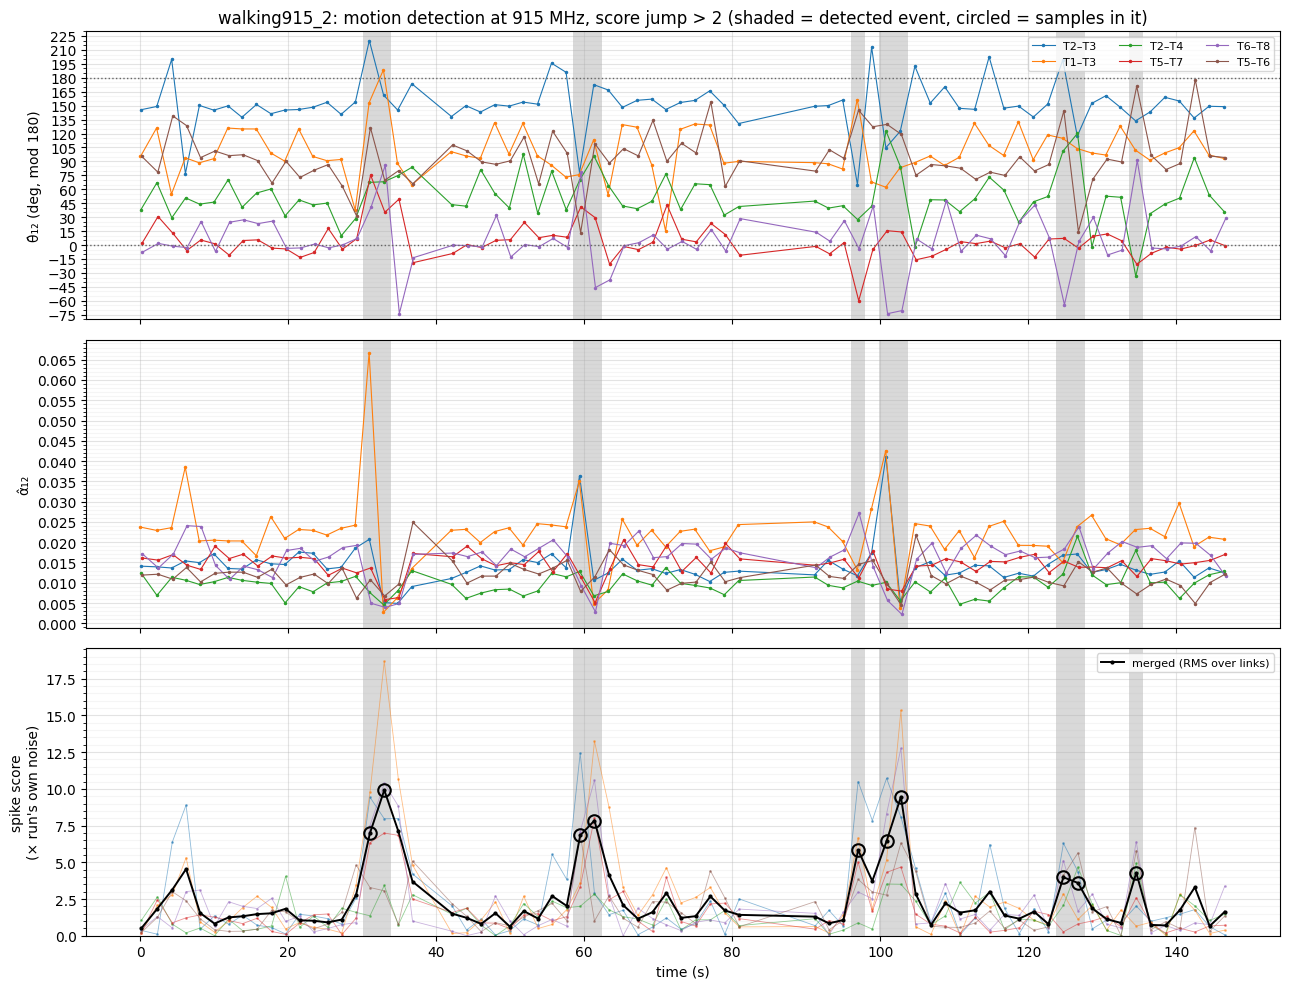

,experiment,links,t_start (s),t_end (s),t_peak (s),peak score,n samples,main links at peak
0,baseline915,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",91.05,91.05,91.05,18.73,1,T2–T3
1,walking915_1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",20.68,22.67,22.67,8.06,2,"T1–T3, T5–T7, T6–T8"
2,walking915_1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",48.70,50.68,50.68,5.92,2,"T1–T3, T5–T7, T6–T8"
3,walking915_1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",103.60,105.68,103.60,7.35,2,"T2–T3, T6–T8, T5–T6"
4,walking915_1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",109.57,109.57,109.57,6.60,1,T5–T7
5,walking915_2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",31.06,32.99,32.99,9.92,2,"T1–T3, T6–T8"
6,walking915_2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",59.47,61.40,61.40,7.84,2,"T1–T3, T5–T7, T6–T8"
7,walking915_2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",97.02,97.02,97.02,5.83,1,"T2–T3, T1–T3"
8,walking915_2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",100.87,102.81,102.81,9.46,2,"T1–T3, T6–T8"
9,walking915_2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",124.77,126.73,124.77,3.98,2,"T2–T3, T6–T8, T5–T6"


In [165]:
# Merged motion detection over several links: one group, scored as the RMS of the link scores, so a spike on several
# links at once stands out more than a spike on one. Uses run_motion from the cell above.
MG_LINKS = [(2, 3), (1, 3), (2, 4), (5, 7), (6, 8), (5, 6)]    # (T1, T2), T1 < T2
# MG_LINKS = [(2, 3), (1, 3), (2, 4), (5, 7), (6, 8), (5, 6), (1,4), (7,8)]    # (T1, T2), T1 < T2
MG_DELTA = 2.0        # jump in the merged score that opens / closes a window (the RMS over links is smoother than
                      # one link's score, so this is lower than MD_DELTA)

mg_events = run_motion([MG_LINKS], MG_DELTA, ["k"], caption="Detected motion events, merged links")

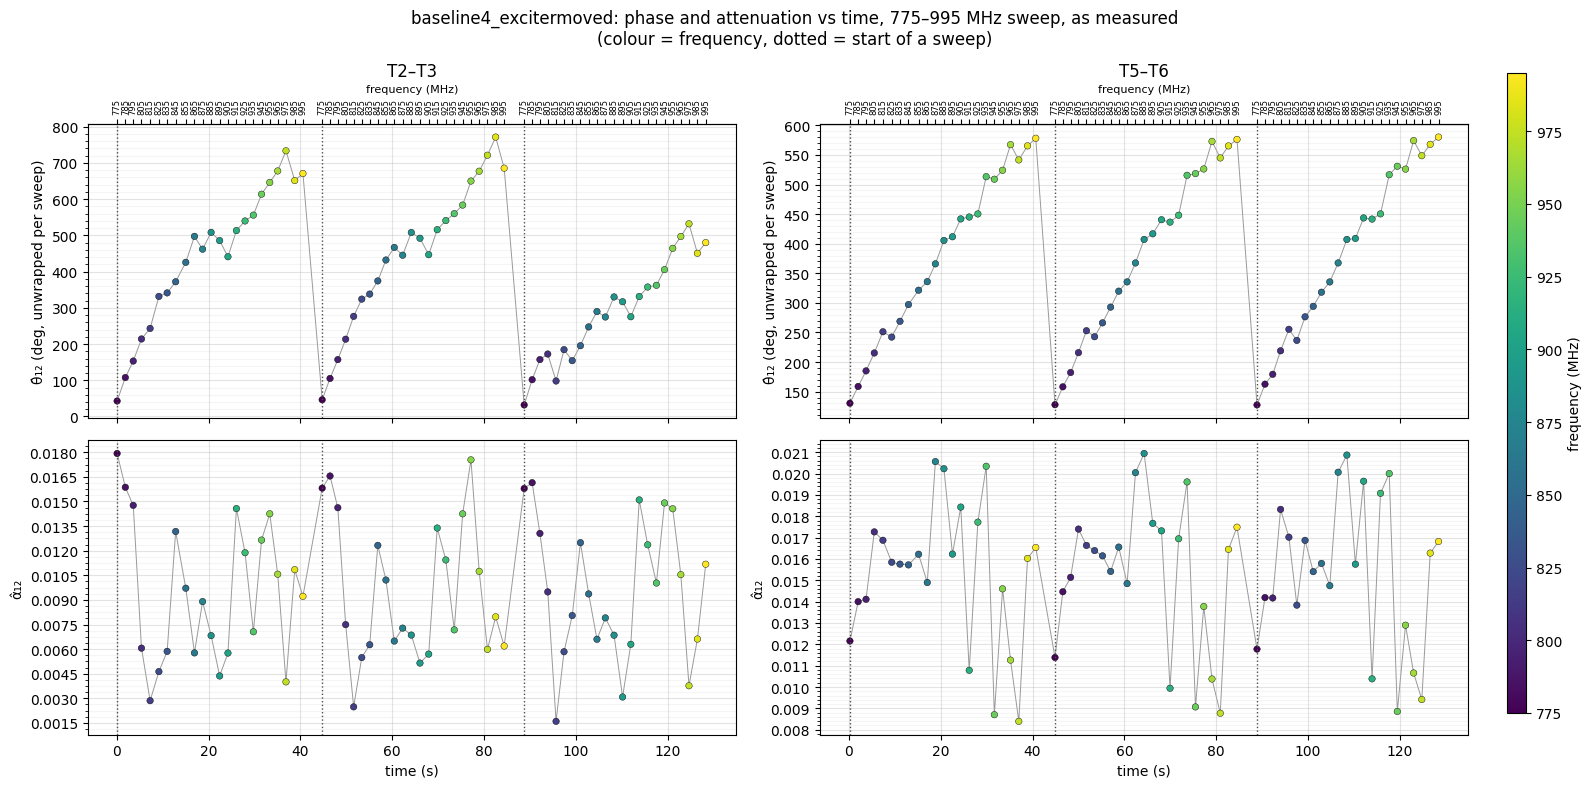

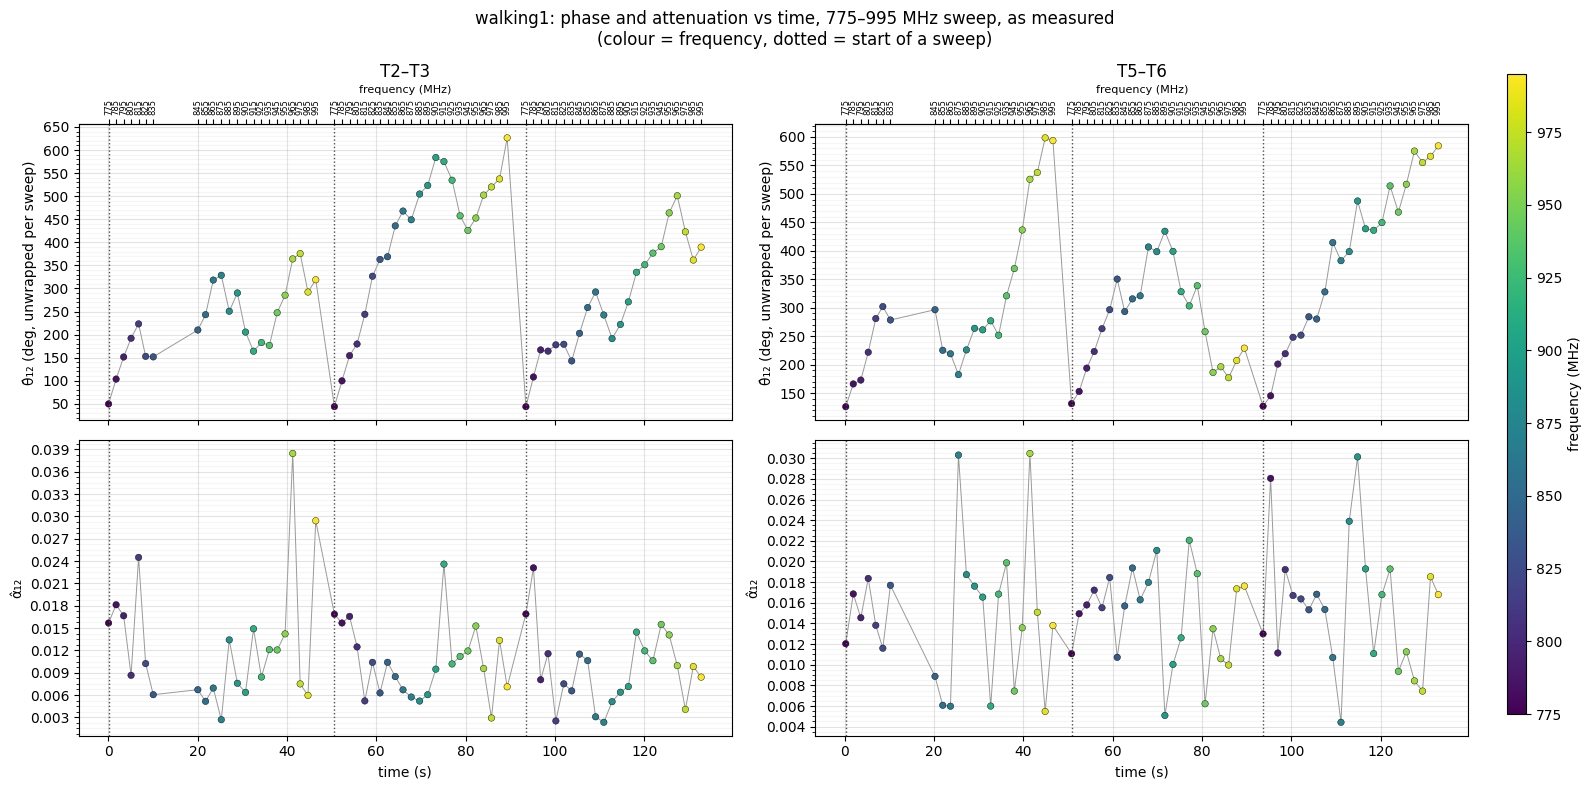

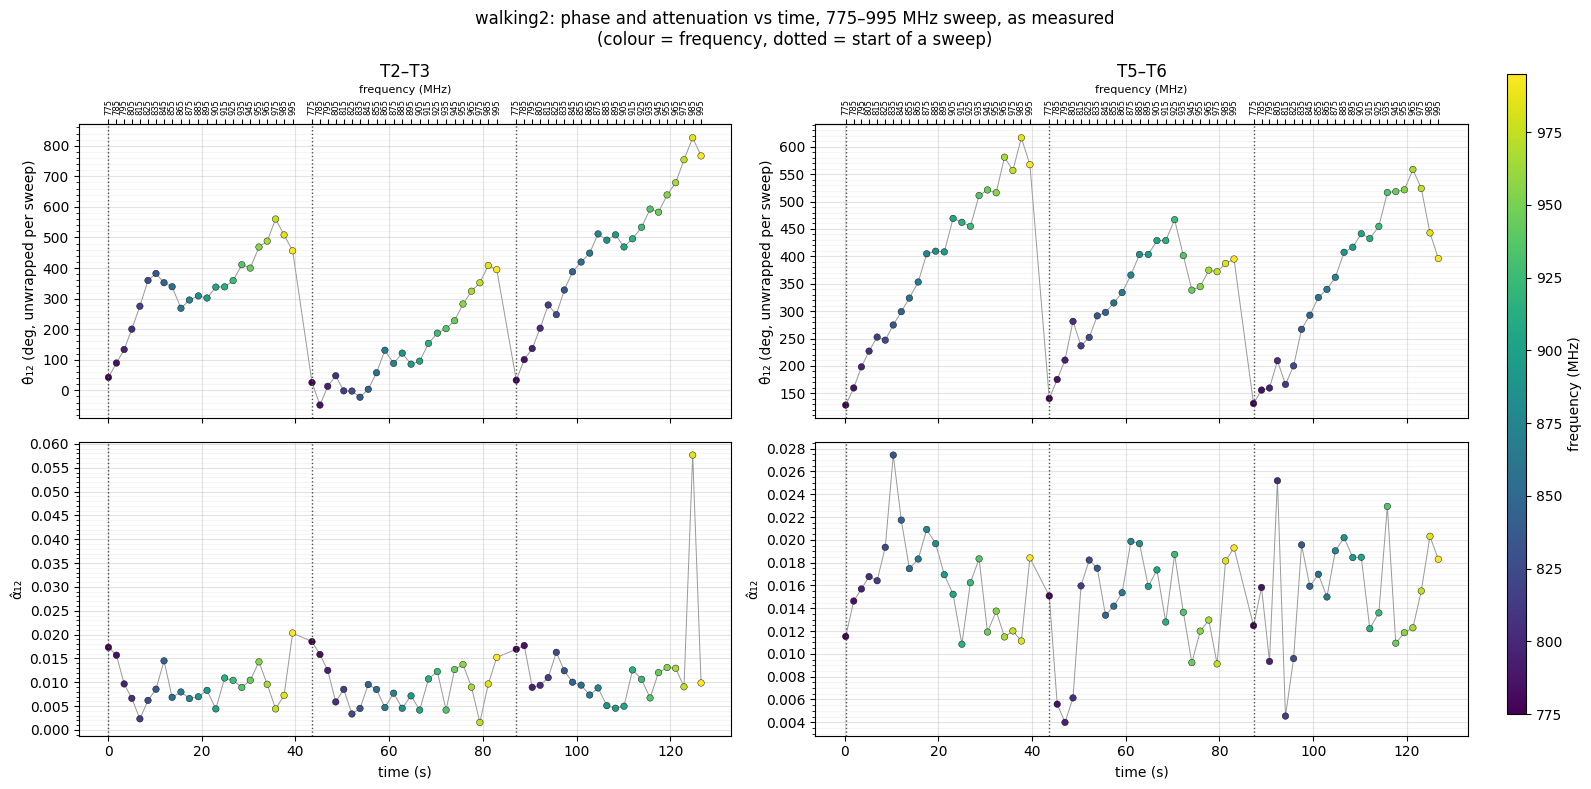

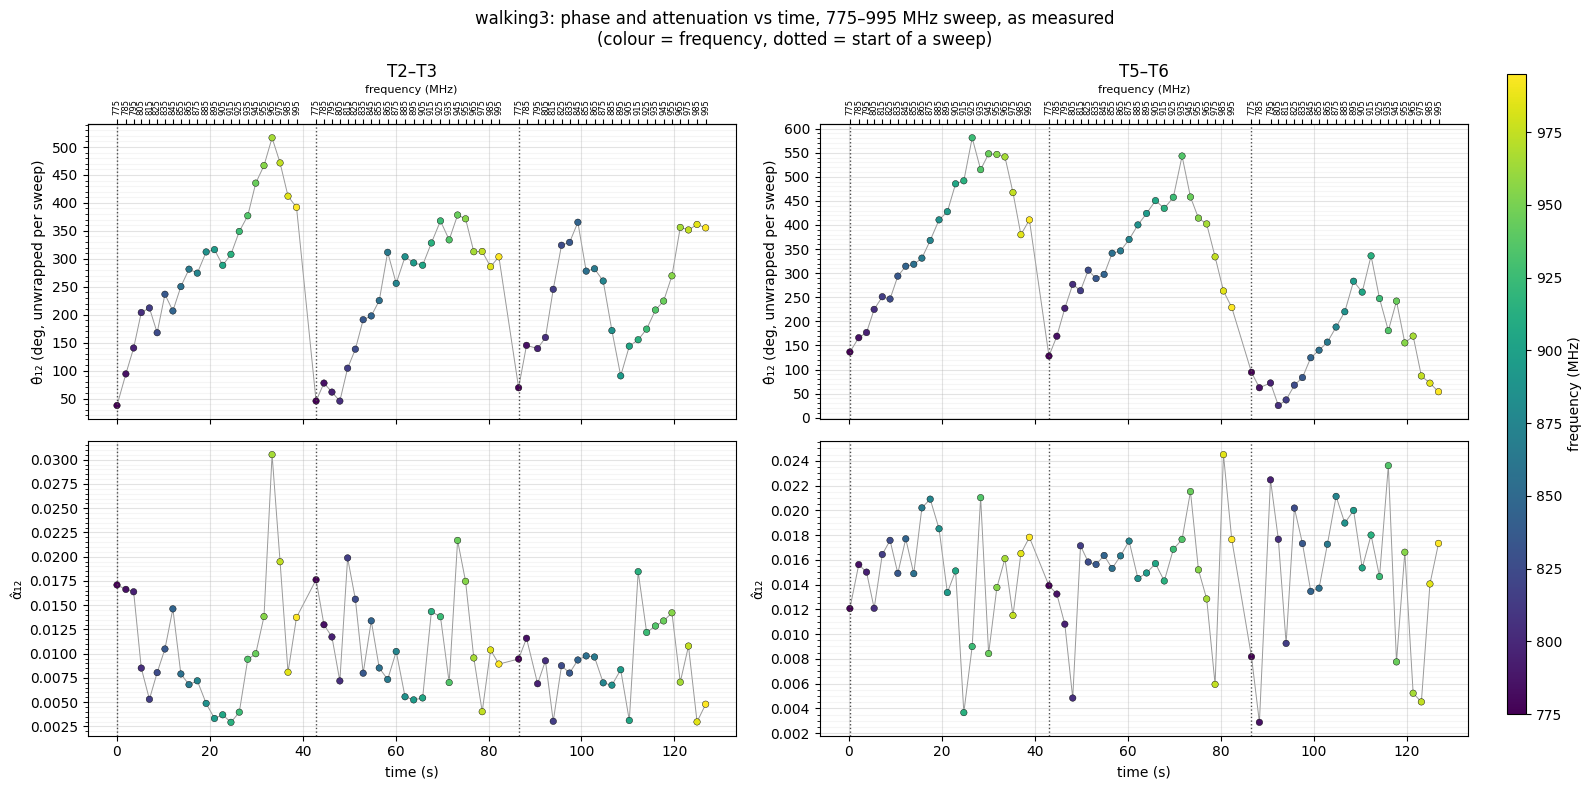

In [168]:
# θ̂ and α̂ of the same links against time for the multi-frequency experiments (775–995 MHz in 23 steps, 3 runs).
# Each run sweeps the frequencies one after another (≈ 1.8 s per step), so a link gets a new sample every step but
# at a different frequency each time. Every sample is coloured by its frequency; the grey line joins the samples in
# time order and dotted vertical lines mark the start of each run (sweep).
# All experiments are plotted as measured (nothing subtracted). The phase is unwrapped with np.unwrap(period=180)
# separately for each sweep (775 → 995 MHz): whenever consecutive samples differ by more than 90°, a multiple of
# 180° is added so the curve continues instead of jumping across the wrap. The unwrap restarts at every sweep.
# MF_BASE (the empty room) is only used by the detection cell below.
# Uses TS_LINKS, tag_num from above.
MF_BASE = "baseline4_excitermoved"
MF_EXPS = [MF_BASE, "walking1", "walking2", "walking3"]
MF_CMAP = plt.cm.viridis


def link_all_freqs(exp_data, a, b):
    # {freq: value} of tags a < b in a nested {T1: {T2: {freq: …}}} dict (links, theta_data or alpha_data)
    for t1, by_t2 in exp_data.items():
        for t2, by_f in by_t2.items():
            if (tag_num(t1), tag_num(t2)) == (a, b):
                return by_f
    raise KeyError(f"link T{a}–T{b} not found")


def link_samples(exp, a, b):
    # -> time, frequency, phase (deg, unwrapped per sweep), attenuation, run start times; all sorted by time
    by_f = link_all_freqs(links[exp], a, b)
    t, f, ph, at = (np.concatenate(x) for x in zip(*[
        (s.time, np.full(len(s.time), freq), np.rad2deg(s.theta), s.attn) for freq, s in by_f.items()]))
    order = np.argsort(t)
    t, f, ph, at = t[order], f[order], ph[order], at[order]
    new_sweep = np.diff(f) < 0                                    # frequency drops back = a new sweep
    sweep = np.concatenate([[0], np.cumsum(new_sweep)])
    # θ̂ is mod 180°: within each sweep remove ±180° jumps between consecutive samples, each sweep on its own
    ph = np.concatenate([np.unwrap(ph[sweep == k], period=180) for k in np.unique(sweep)])
    run_starts = np.concatenate([[t[0]], t[1:][new_sweep]])
    return t, f, ph, at, run_starts


mf_freqs = np.array(sorted(link_all_freqs(links[MF_BASE], *TS_LINKS[0])))
mf_norm = plt.Normalize(mf_freqs.min(), mf_freqs.max())

for exp in MF_EXPS:
    fig, axes = plt.subplots(2, len(TS_LINKS), figsize=(16, 8), sharex=True, squeeze=False)
    for col, (a, b) in enumerate(TS_LINKS):
        ax_th, ax_at = axes[0, col], axes[1, col]
        t, f, ph, at, run_starts = link_samples(exp, a, b)
        for ax, y in ((ax_th, ph), (ax_at, at)):
            ax.plot(t, y, "-", color="0.6", lw=0.7, zorder=1)
            ax.scatter(t, y, c=f, cmap=MF_CMAP, norm=mf_norm, s=22, edgecolors="k", linewidths=0.3, zorder=2)
            for rs in run_starts:
                ax.axvline(rs, color="0.3", ls=":", lw=1)
            ax.grid(which="major", alpha=0.35)
            ax.grid(which="minor", alpha=0.12)
        ax_th.yaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 1.5, 3, 5, 10]))   # multiples of 15°
        ax_th.yaxis.set_minor_locator(AutoMinorLocator())
        ax_th.set_ylabel("θ̂₁₂ (deg, unwrapped per sweep)")
        ax_at.set_ylabel("α̂₁₂")
        ax_at.yaxis.set_major_locator(MaxNLocator(nbins=15))
        ax_at.yaxis.set_minor_locator(AutoMinorLocator())
        ax_at.set_xlabel("time (s)")
        sec = ax_th.secondary_xaxis("top")    # second x axis: frequency of each sample, at its time
        sec.set_xticks(t, labels=[f"{v:g}" for v in f], rotation=90, fontsize=6)
        sec.set_xlabel("frequency (MHz)", fontsize=8)
        ax_th.set_title(f"T{a}–T{b}")
    fig.suptitle(f"{exp}: phase and attenuation vs time, 775–995 MHz sweep, as measured\n"
                 f"(colour = frequency, dotted = start of a sweep)")
    fig.tight_layout(rect=(0, 0, 0.93, 1))
    cax = fig.add_axes([0.945, 0.1, 0.012, 0.8])
    fig.colorbar(plt.cm.ScalarMappable(norm=mf_norm, cmap=MF_CMAP), cax=cax, label="frequency (MHz)")
    plt.show()

merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6: empty-room check, score vs baseline noise must exceed 20.65 (p99 of baseline4_excitermoved)


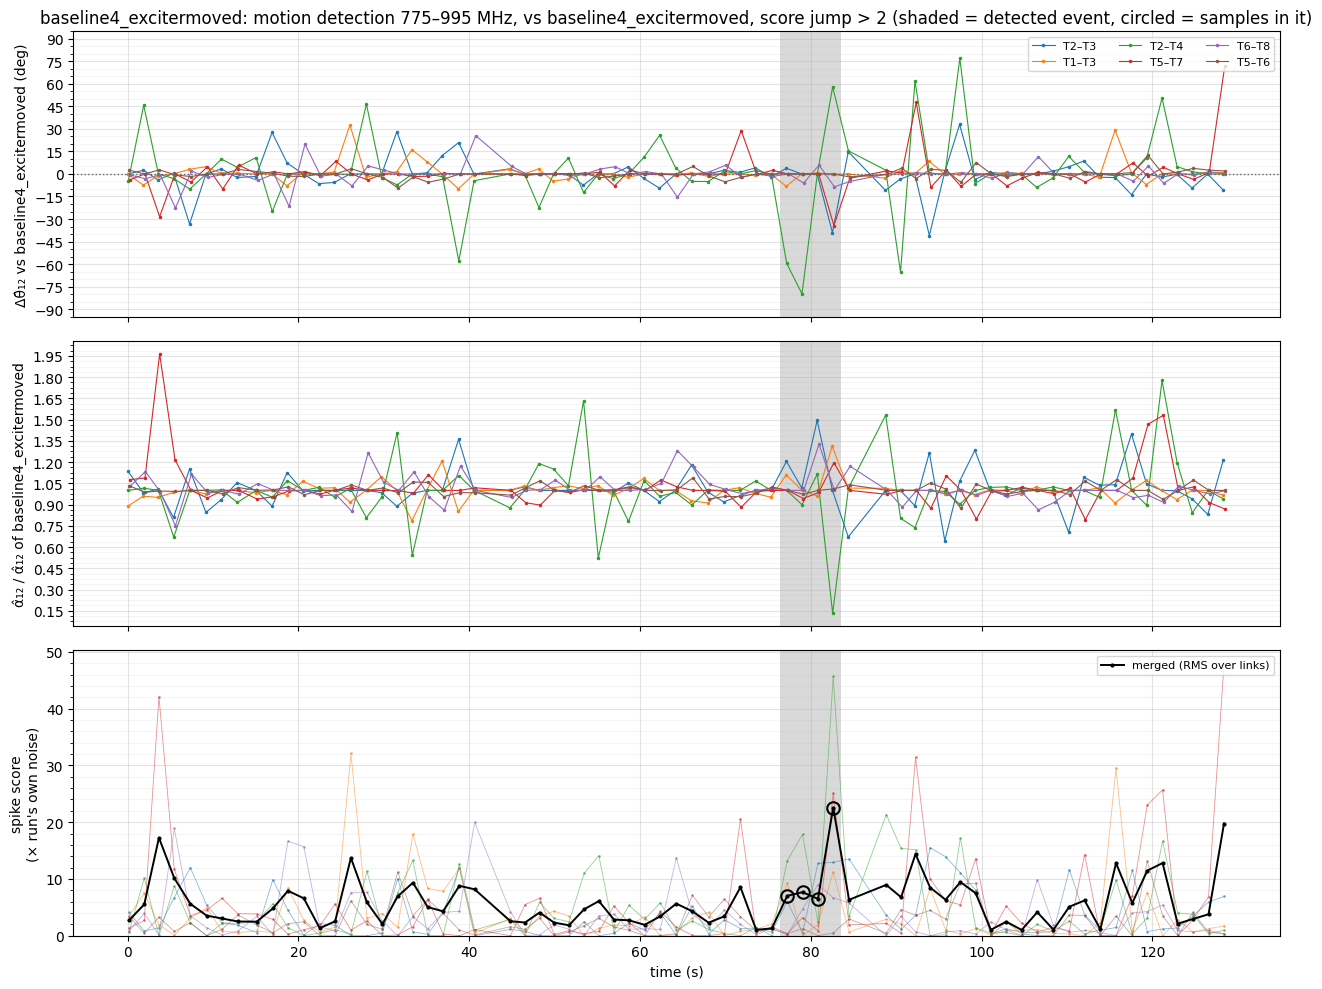

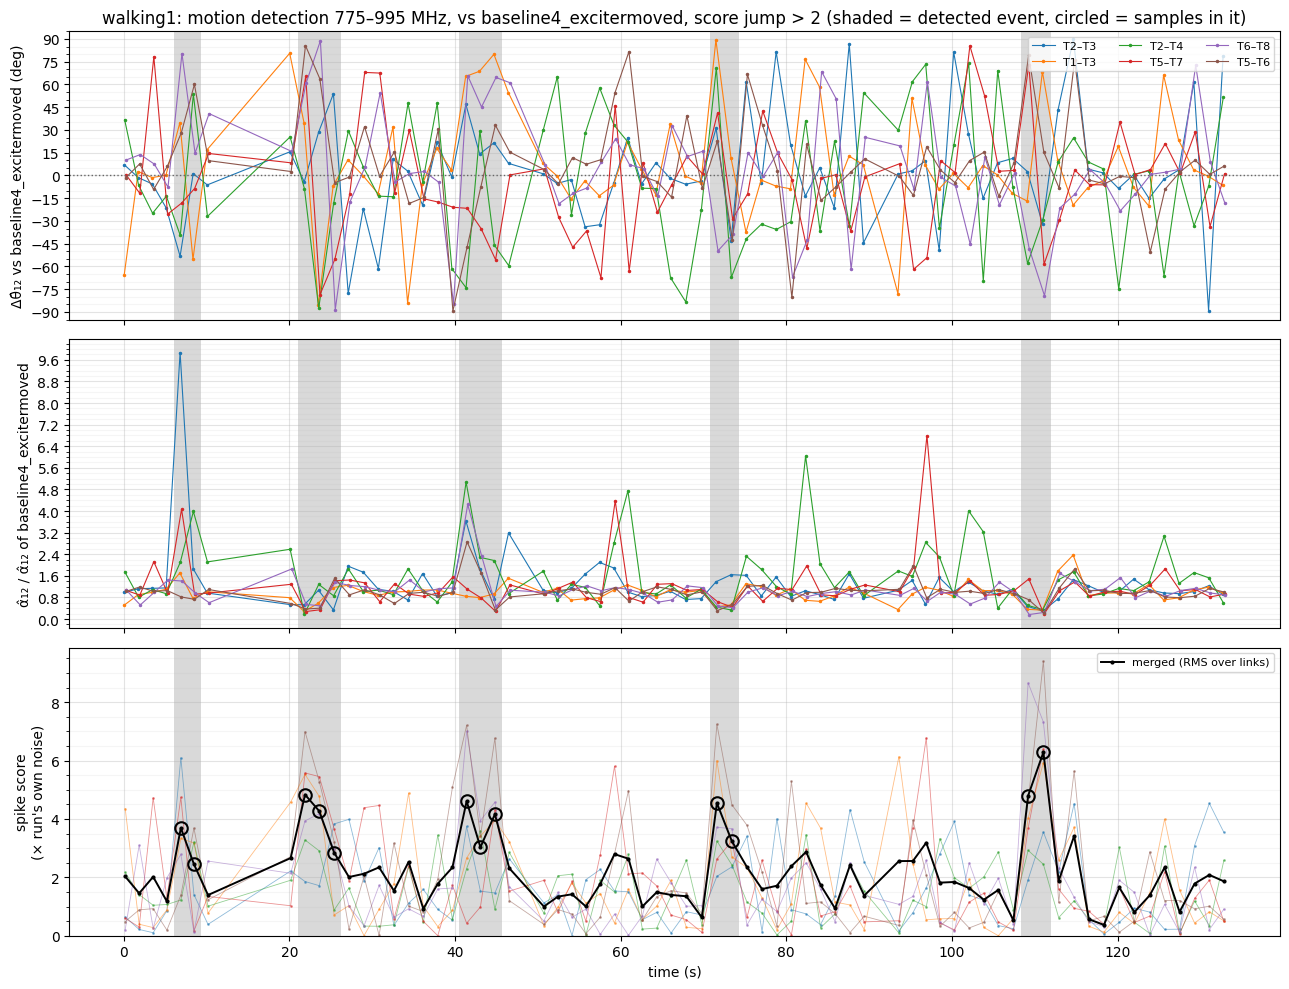

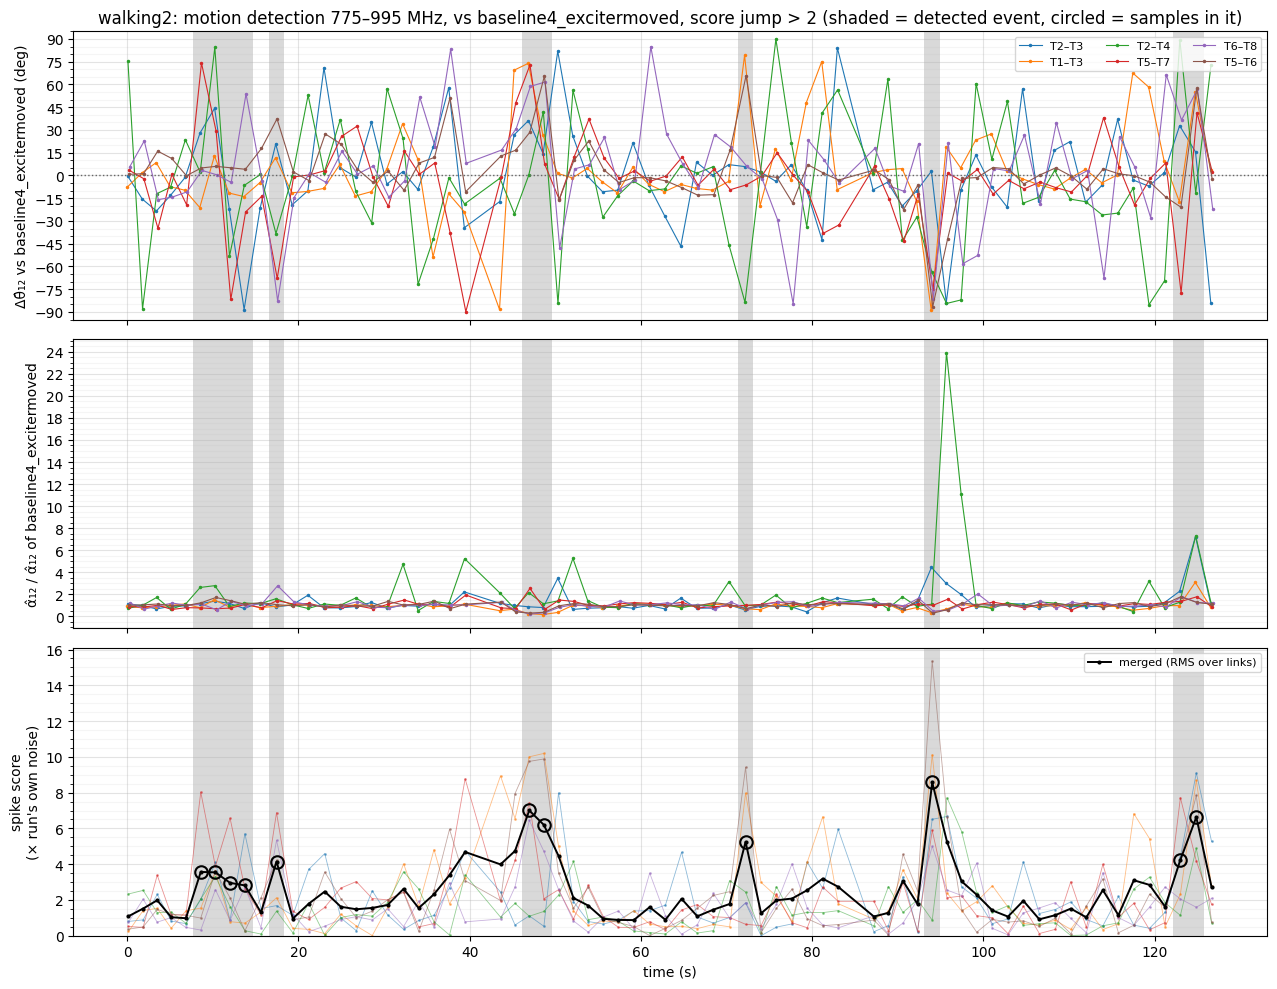

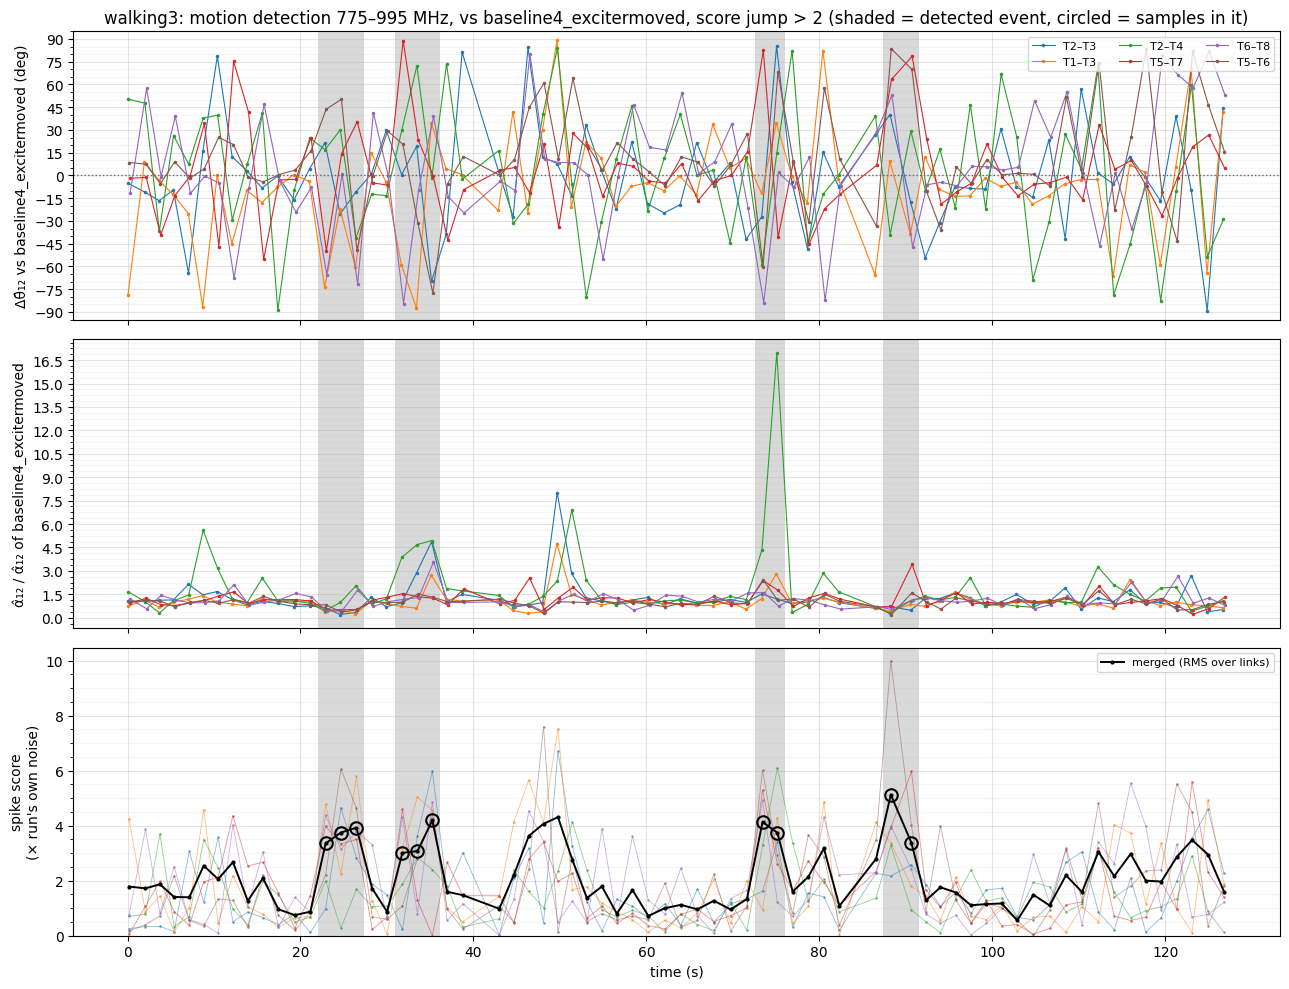

,experiment,links,t_start (s),t_end (s),t_peak (s),peak score,n samples,main links at peak
0,baseline4_excitermoved,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",77.24,82.62,82.62,22.56,4,"T2–T4, T5–T7"
1,walking1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",6.89,8.47,6.89,3.69,2,"T2–T3, T5–T7"
2,walking1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",21.88,25.40,21.88,4.83,3,"T1–T3, T5–T7, T5–T6"
3,walking1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",41.40,44.81,41.40,4.61,3,"T6–T8, T5–T6"
4,walking1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",71.62,73.43,71.62,4.54,2,"T1–T3, T5–T6"
5,walking1,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",109.21,111.05,111.05,6.28,2,"T5–T7, T6–T8, T5–T6"
6,walking2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",8.61,13.76,8.61,3.57,4,T5–T7
7,walking2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",17.45,17.45,17.45,4.14,1,"T5–T7, T6–T8, T5–T6"
8,walking2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",46.97,48.68,46.97,7.01,2,"T1–T3, T5–T7, T5–T6"
9,walking2,"merged T2–T3, T1–T3, T2–T4, T5–T7, T6–T8, T5–T6",72.23,72.23,72.23,5.25,1,"T1–T3, T5–T6"


In [167]:
# Motion detection on the multi-frequency experiments, using the baseline-subtracted features from the cell above.
# Each link becomes one time series over all frequencies (≈ 1.8 s per sample, 69 samples), where every sample is
# compared with the empty room (MF_BASE) at its own frequency:
#   phase: θ̂ − θ̂_base(f)  (mod 180°; plotted wrapped to (−90°, 90°])
#   attn : α̂ / α̂_base(f)   (a ratio, so the log-attenuation residual of `residuals` is log α̂ − log α̂_base)
# These series go through exactly the same algorithm as the 915 MHz runs (run_motion: rolling-median residual,
# score × the run's own noise, jump windows, empty-room check). The empty-room check uses MF_BASE compared with its
# own per-frequency median; with only 3 runs per frequency that baseline noise is on the low side.
# Uses run_motion, TS_LINKS, TS_COLORS, MG_LINKS from above and link_all_freqs, MF_BASE, MF_EXPS from the cell above.
MF_DELTA = 3.0        # jump in a single link's score that opens / closes a window
MF_MG_DELTA = 2.0     # same for the merged score


def mf_delta_series(exp, a, b, base=MF_BASE):
    # -> LinkSeries over all frequencies in time order, θ̂ and α̂ relative to `base` at the same frequency
    th_base, at_base = link_all_freqs(theta_data[base], a, b), link_all_freqs(alpha_data[base], a, b)
    parts = [(s.time_dir1, s.time_dir2, (s.theta - th_base[f]) % np.pi, s.attn / at_base[f])
             for f, s in link_all_freqs(links[exp], a, b).items()]
    d1, d2, th, at = (np.concatenate(x) for x in zip(*parts))
    order = np.argsort((d1 + d2) / 2)
    return LinkSeries(time_dir1=d1[order], time_dir2=d2[order], theta=th[order], attn=at[order])


mf_kw = dict(exps=MF_EXPS, source=mf_delta_series, baseline=MF_BASE, what=f"775–995 MHz, vs {MF_BASE}",
             phase_label=f"Δθ̂₁₂ vs {MF_BASE} (deg)", attn_label=f"α̂₁₂ / α̂₁₂ of {MF_BASE}",
             phase_fn=lambda th: (np.rad2deg(th) + 90) % 180 - 90)     # difference wrapped to (−90°, 90°]

# # single links, each its own group
# mf_events = run_motion([[link] for link in TS_LINKS], MF_DELTA, TS_COLORS,
#                        caption="Detected motion events, multi-frequency (baseline subtracted)", **mf_kw)

# merged links
mf_mg_events = run_motion([MG_LINKS], MF_MG_DELTA, ["k"],
                          caption="Detected motion events, multi-frequency, merged links", **mf_kw)